# Pronóstico de Demanda con Time Series Foundation Models (TSFM)

**Chronos-Bolt (Amazon) aplicado a las ventas semanales de 45 tiendas de Walmart**

---

Autor: Diego Yeferson Quispe Huamani

---


### Contenido del cuaderno

1. **Introducción:** definición del problema y mapa de proceso
2. **Configuración del entorno** (librerías, Spark y descarga del dataset desde Kaggle)
3. **EDA:** análisis exploratorio con PySpark y Pandas
4. **Modelado:** Chronos-Bolt — arquitectura Transformer, tokenización de la serie y pronóstico zero-shot
5. **Evaluación:** métricas y comparación contra Naive, Auto-ARIMA, Prophet y XGBoost
6. **Propuesta de despliegue** en producción
7. **Conclusiones**

# <font color=orange>**1.- Introducción**</font>

## **1.1 Definición del problema**

Walmart maneja cientos de tiendas y cada semana tiene que decidir cuánto inventario enviar a cada una, cuánto personal programar y cuánta caja va a necesitar. Si se queda corto hay **quiebres de stock** (ventas perdidas y clientes molestos); si se pasa, hay **sobrestock** (capital inmovilizado, mermas y costos de almacén). Todo esto depende de tener un buen **pronóstico de demanda**.

El problema que abordamos es:

> **Pronosticar las ventas semanales (`Weekly_Sales`) de las 45 tiendas de Walmart para las próximas 12 semanas (≈ 1 trimestre)**, con intervalos de incertidumbre, usando un **modelo fundacional de series de tiempo (TSFM)** sin entrenarlo sobre estos datos (*zero-shot*), y comprobar si es competitivo frente a los modelos tradicionales.

**¿Por qué un TSFM?**
Con ARIMA o Prophet hay que ajustar **un modelo por cada tienda** (45 modelos) y repetir el ajuste cada vez que llega data nueva. Un TSFM como **Chronos-Bolt** ya fue preentrenado con ~100 mil millones de observaciones de series reales y sintéticas, así que con **un solo modelo** y una sola llamada pronosticamos las 45 tiendas a la vez.

**Horizonte elegido: 12 semanas.**

 Es el horizonte típico de planificación de compras/inventario en retail (un trimestre) y es suficiente para ver si el modelo capta tendencia y estacionalidad.

## 1.2 Dataset

| **Campo** | **Detalle** |
|:---|:---|
| **Nombre** | **Walmart Dataset** — "Walmart Store Sales Prediction - Regression Problem" |
| **Fuente** | Kaggle, publicado por **Yasser H.** |
| **Enlace original** | [Kaggle – Walmart Dataset](https://www.kaggle.com/datasets/yasserh/walmart-dataset) |
| **Origen de los datos** | Datos históricos de ventas de **45 tiendas de Walmart en EE.UU.** Datos liberados por la propia empresa en la competencia de Kaggle *Walmart Recruiting – Store Sales Forecasting*. [Ver competencia](https://www.kaggle.com/competitions/walmart-recruiting-store-sales-forecasting) |
| **Archivo** | `Walmart.csv` — **6,435 filas × 8 columnas** |
| **Periodo** | del **05/02/2010** al **26/10/2012** (**143 semanas** por tienda) |
| **Granularidad** | Semanal (la semana cierra el viernes) por tienda |


**Variables**

| Columna | Descripción |
|---|---|
| `Store` | Número de tienda (1 a 45) |
| `Date` | Fecha de la semana de ventas (formato dd-mm-aaaa) |
| `Weekly_Sales` | **Ventas de la semana en USD (variable objetivo)** |
| `Holiday_Flag` | 1 si la semana tiene feriado especial (Super Bowl, Labor Day, Thanksgiving, Navidad), 0 si no |
| `Temperature` | Temperatura promedio de la región (°F) |
| `Fuel_Price` | Precio del combustible en la región (USD / galón) |
| `CPI` | Índice de precios al consumidor |
| `Unemployment` | Tasa de desempleo de la región (%) |


Es un dataset real, limpio y muy usado en la comunidad de Kaggle, tiene 45 series de tiempo paralelas: ideal para probar un modelo fundacional sobre **todas las tiendas** y no solo sobre una.

## **1.3 Mapa de proceso**

El flujo completo del proyecto va desde la descarga del dato en Kaggle hasta la propuesta de despliegue:

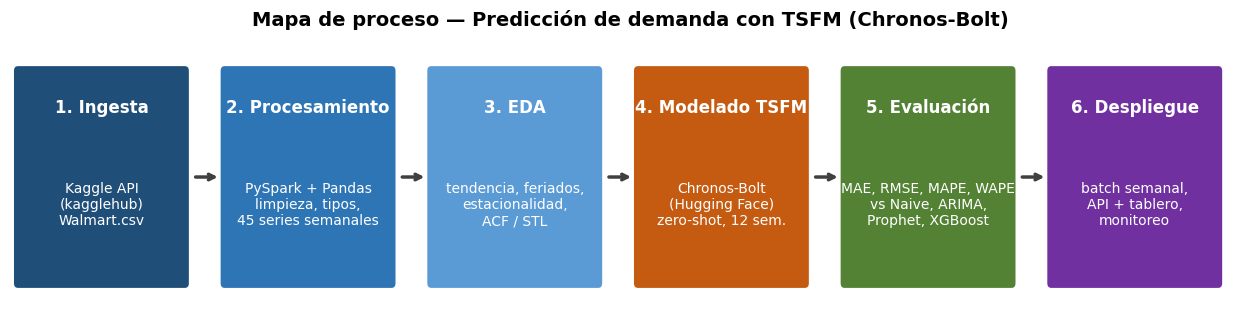

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

pasos = [
    ("1. Ingesta", "Kaggle API\n(kagglehub)\nWalmart.csv", "#1f4e79"),
    ("2. Procesamiento", "PySpark + Pandas\nlimpieza, tipos,\n45 series semanales", "#2e75b6"),
    ("3. EDA", "tendencia, feriados,\nestacionalidad,\nACF / STL", "#5b9bd5"),
    ("4. Modelado TSFM", "Chronos-Bolt\n(Hugging Face)\nzero-shot, 12 sem.", "#c55a11"),
    ("5. Evaluación", "MAE, RMSE, MAPE, WAPE\nvs Naive, ARIMA,\nProphet, XGBoost", "#548235"),
    ("6. Despliegue", "batch semanal,\nAPI + tablero,\nmonitoreo", "#7030a0"),
]

fig, ax = plt.subplots(figsize=(16, 3.6))
ax.set_xlim(0, len(pasos) * 2.6); ax.set_ylim(0, 3); ax.axis("off")
for i, (titulo, detalle, color) in enumerate(pasos):
    x = i * 2.6 + 0.1
    ax.add_patch(FancyBboxPatch((x, 0.3), 2.1, 2.3, boxstyle="round,pad=0.05", fc=color, ec="none"))
    ax.text(x + 1.05, 2.2, titulo, ha="center", va="center", color="white", fontsize=12, weight="bold")
    ax.text(x + 1.05, 1.15, detalle, ha="center", va="center", color="white", fontsize=10)
    if i < len(pasos) - 1:
        ax.annotate("", xy=(x + 2.55, 1.45), xytext=(x + 2.2, 1.45),
                    arrowprops=dict(arrowstyle="->", lw=2.5, color="#404040"))
ax.set_title("Mapa de proceso — Predicción de demanda con TSFM (Chronos-Bolt)", fontsize=14, weight="bold")
plt.show()

El mapa resume la lógica del proyecto: **ingesta** desde Kaggle, **procesamiento** con PySpark, **EDA** para entender la serie, **modelado** con el TSFM vía Hugging Face, **evaluación** contra modelos clásicos y finalmente la **propuesta de despliegue**.

# <font color=orange>**2.- Configuramos el entorno**</font>

Antes de ejecutar, activamos la GPU para que la inferencia sea más rápida (en CPU también funciona, Chronos-Bolt es liviano):

**Entorno de ejecución → Cambiar tipo de entorno de ejecución → Acelerador de hardware: GPU (T4)**

In [ ]:
%%time
# Instalamos Chronos (Amazon), pmdarima (Auto-ARIMA) y kagglehub (descarga de Kaggle).
# Prophet, XGBoost, PySpark, statsmodels y scikit-learn ya vienen en Colab.
!pip install -q chronos-forecasting pmdarima kagglehub

In [ ]:
# Librerías comunes
import os, time, shutil, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").disabled = True   # silencia los logs de Prophet
logging.getLogger("prophet").disabled = True

plt.style.use("ggplot")
from matplotlib.pylab import rcParams
rcParams["figure.figsize"] = 14, 5
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Fecha de ejecución:", pd.Timestamp.today().strftime("%Y-%m-%d %H:%M"))

Fecha de ejecución: 2026-09-27 01:51


## **2.1 Sesión de Spark**

Creamos una `SparkSession`, que es el punto de entrada para trabajar con DataFrames distribuidos. La usaremos para la carga y las agregaciones del EDA.

In [ ]:
%%time
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = SparkSession.builder.appName("TSFM_Walmart_Chronos").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
spark

CPU times: user 460 ms, sys: 54.8 ms, total: 515 ms
Wall time: 10.9 s


## **2.2 Descargamos dataset desde Kaggle**

Usamos `kagglehub`, la librería oficial de Kaggle, para descargar el dataset público **yasserh/walmart-dataset**.

Como es un dataset público no hace falta aceptar reglas de competencia.

Si la descarga falla (por ejemplo, por límite de Kaggle), hay que subir manualmente el `Walmart.csv` descargado desde el enlace.

In [ ]:
ARCHIVO = "Walmart.csv"

if not os.path.exists(ARCHIVO):
    try:
        import kagglehub
        ruta = kagglehub.dataset_download("yasserh/walmart-dataset")
        shutil.copy(os.path.join(ruta, "Walmart.csv"), ARCHIVO)
    except Exception as e:
        print("No se pudo descargar con kagglehub:", e)
        print("Sube el archivo Walmart.csv descargado de https://www.kaggle.com/datasets/yasserh/walmart-dataset")
        from google.colab import files
        files.upload()

print("Archivo listo:", os.path.abspath(ARCHIVO), "|", round(os.path.getsize(ARCHIVO) / 1024, 1), "KB")

Extracting files...
Archivo listo: /content/Walmart.csv | 355.2 KB


# <font color=orange>**3.- EDA: Análisis Exploratorio de Datos**</font>

## **3.1 Carga con PySpark y revisión de la estructura**

In [ ]:
df_spark = spark.read.csv(ARCHIVO, header=True, inferSchema=True)

# La fecha viene como texto dd-MM-yyyy: la convertimos a tipo fecha
df_spark = df_spark.withColumn("Date", F.to_date("Date", "dd-MM-yyyy"))

df_spark.printSchema()
print(f"Filas: {df_spark.count()} | Columnas: {len(df_spark.columns)}")
df_spark.show(5)

root
 |-- Store: integer (nullable = true)
 |-- Date: date (nullable = true)
 |-- Weekly_Sales: double (nullable = true)
 |-- Holiday_Flag: integer (nullable = true)
 |-- Temperature: double (nullable = true)
 |-- Fuel_Price: double (nullable = true)
 |-- CPI: double (nullable = true)
 |-- Unemployment: double (nullable = true)

Filas: 6435 | Columnas: 8
+-----+----------+------------+------------+-----------+----------+-----------+------------+
|Store|      Date|Weekly_Sales|Holiday_Flag|Temperature|Fuel_Price|        CPI|Unemployment|
+-----+----------+------------+------------+-----------+----------+-----------+------------+
|    1|2010-02-05|   1643690.9|           0|      42.31|     2.572|211.0963582|       8.106|
|    1|2010-02-12|  1641957.44|           1|      38.51|     2.548|211.2421698|       8.106|
|    1|2010-02-19|  1611968.17|           0|      39.93|     2.514|211.2891429|       8.106|
|    1|2010-02-26|  1409727.59|           0|      46.63|     2.561|211.3196429|      

Spark infiere bien los tipos numéricos (`Weekly_Sales`, `Temperature`, `CPI`, etc.) y ya tenemos `Date` como fecha real. Son **6,435 registros** y **8 columnas**, que es exactamente 45 tiendas × 143 semanas.

In [ ]:
# Calidad de datos: nulos por columna, duplicados y rango de fechas
nulos = df_spark.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df_spark.columns])
print("Nulos por columna:"); nulos.show()

print("Registros duplicados:", df_spark.count() - df_spark.dropDuplicates().count())

df_spark.select(F.min("Date").alias("fecha_inicio"), F.max("Date").alias("fecha_fin"),
                F.countDistinct("Store").alias("tiendas"),
                F.countDistinct("Date").alias("semanas")).show()

# ¿Todas las tiendas tienen la serie completa?
df_spark.groupBy("Store").count().select(F.min("count").alias("min_semanas"),
                                          F.max("count").alias("max_semanas")).show()

Nulos por columna:
+-----+----+------------+------------+-----------+----------+---+------------+
|Store|Date|Weekly_Sales|Holiday_Flag|Temperature|Fuel_Price|CPI|Unemployment|
+-----+----+------------+------------+-----------+----------+---+------------+
|    0|   0|           0|           0|          0|         0|  0|           0|
+-----+----+------------+------------+-----------+----------+---+------------+

Registros duplicados: 0
+------------+----------+-------+-------+
|fecha_inicio| fecha_fin|tiendas|semanas|
+------------+----------+-------+-------+
|  2010-02-05|2012-10-26|     45|    143|
+------------+----------+-------+-------+

+-----------+-----------+
|min_semanas|max_semanas|
+-----------+-----------+
|        143|        143|
+-----------+-----------+



La data está **limpia**: no hay nulos ni duplicados, y las 45 tiendas tienen **las 143 semanas completas** (del 05/02/2010 al 26/10/2012). Esto es importante porque los modelos de series de tiempo necesitan una frecuencia regular y sin huecos.

In [ ]:
# Estadística descriptiva (Spark) de las variables numéricas
df_spark.select("Weekly_Sales", "Temperature", "Fuel_Price", "CPI", "Unemployment").describe().show()

+-------+------------------+------------------+-------------------+-----------------+------------------+
|summary|      Weekly_Sales|       Temperature|         Fuel_Price|              CPI|      Unemployment|
+-------+------------------+------------------+-------------------+-----------------+------------------+
|  count|              6435|              6435|               6435|             6435|              6435|
|   mean|1046964.8775617732| 60.66378243978229|  3.358606837606832|171.5783938487799| 7.999151048951067|
| stddev| 564366.6220536977|18.444932875811585|0.45901970719285223|39.35671229566419|1.8758847818627944|
|    min|         209986.25|             -2.06|              2.472|          126.064|             3.879|
|    max|        3818686.45|            100.14|              4.468|      227.2328068|            14.313|
+-------+------------------+------------------+-------------------+-----------------+------------------+



La venta semanal promedio por tienda es de **≈ 1.05 millones USD**, pero con una desviación de **≈ 564 mil**, es decir, hay mucha diferencia entre tiendas. El mínimo es de ~210 mil y el máximo de **3.82 millones** (una semana de diciembre). Las variables externas tienen rangos razonables: temperatura de −2 °F a 100 °F, combustible entre 2.47 y 4.47 USD/galón y desempleo entre 3.9% y 14.3%.

## **3.2 Agregaciones con PySpark: tiendas, años y feriados**

In [ ]:
# Ranking de tiendas por venta promedio semanal
ventas_tienda = (df_spark.groupBy("Store")
                 .agg(F.round(F.avg("Weekly_Sales"), 0).alias("venta_prom_semanal"),
                      F.round(F.sum("Weekly_Sales") / 1e6, 2).alias("venta_total_MM"))
                 .orderBy(F.desc("venta_prom_semanal")))
ventas_tienda.show(10)

+-----+------------------+--------------+
|Store|venta_prom_semanal|venta_total_MM|
+-----+------------------+--------------+
|   20|         2107677.0|         301.4|
|    4|         2094713.0|        299.54|
|   14|         2020978.0|         289.0|
|   13|         2003620.0|        286.52|
|    2|         1925751.0|        275.38|
|   10|         1899425.0|        271.62|
|   27|         1775216.0|        253.86|
|    6|         1564728.0|        223.76|
|    1|         1555264.0|         222.4|
|   39|         1450668.0|        207.45|
+-----+------------------+--------------+
only showing top 10 rows


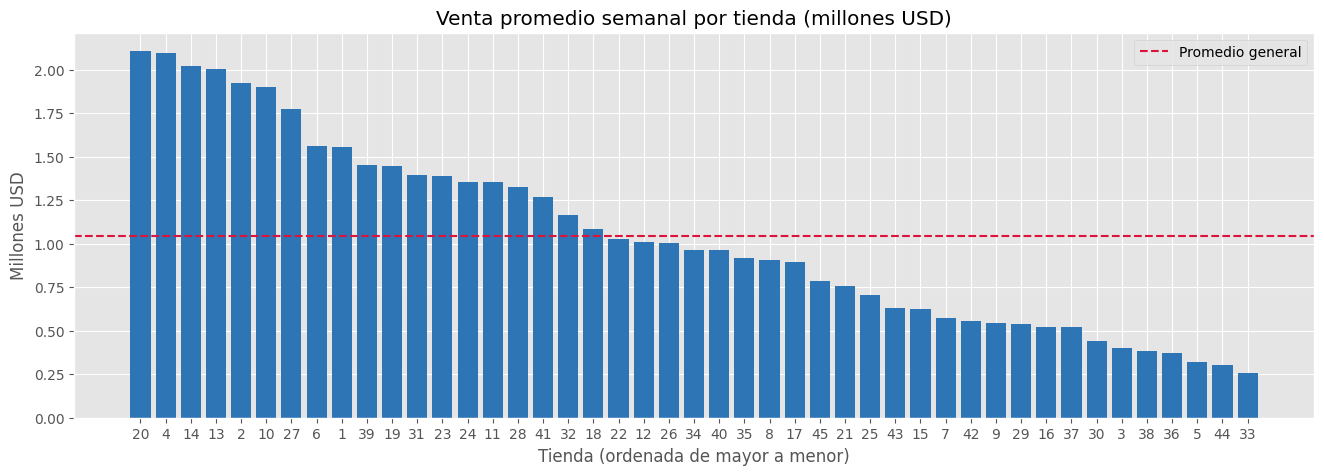

In [ ]:
pdf_tienda = ventas_tienda.toPandas().sort_values("venta_prom_semanal", ascending=False)

plt.figure(figsize=(16, 5))
plt.bar(pdf_tienda["Store"].astype(str), pdf_tienda["venta_prom_semanal"] / 1e6, color="#2e75b6")
plt.axhline(pdf_tienda["venta_prom_semanal"].mean() / 1e6, color="crimson", ls="--", label="Promedio general")
plt.title("Venta promedio semanal por tienda (millones USD)")
plt.xlabel("Tienda (ordenada de mayor a menor)"); plt.ylabel("Millones USD")
plt.legend(); plt.show()

Hay tiendas muy grandes (la **20** y la **4** superan los **2.1 millones** por semana) y tiendas pequeñas como la **33**, que vende ~0.26 millones: una diferencia de **8 veces**. Por eso para comparar modelos no basta con el error en dólares; también usaremos métricas porcentuales (MAPE y WAPE).

In [ ]:
# Impacto de los feriados usando Spark SQL
df_spark.createOrReplaceTempView("walmart")

spark.sql("""
    SELECT CASE WHEN Holiday_Flag = 1 THEN 'Semana con feriado' ELSE 'Semana normal' END AS tipo_semana,
           COUNT(*)                        AS registros,
           ROUND(AVG(Weekly_Sales), 0)     AS venta_promedio,
           ROUND(PERCENTILE_APPROX(Weekly_Sales, 0.5), 0) AS venta_mediana
    FROM walmart
    GROUP BY Holiday_Flag
""").show()

spark.sql("""
    SELECT YEAR(Date) AS anio, COUNT(DISTINCT Date) AS semanas,
           ROUND(SUM(Weekly_Sales) / 1e6, 1) AS venta_total_MM,
           ROUND(AVG(Weekly_Sales), 0) AS venta_prom_tienda_semana
    FROM walmart GROUP BY YEAR(Date) ORDER BY anio
""").show()

+------------------+---------+--------------+-------------+
|       tipo_semana|registros|venta_promedio|venta_mediana|
+------------------+---------+--------------+-------------+
|Semana con feriado|      450|     1122888.0|    1015684.0|
|     Semana normal|     5985|     1041256.0|     955914.0|
+------------------+---------+--------------+-------------+

+----+-------+--------------+------------------------+
|anio|semanas|venta_total_MM|venta_prom_tienda_semana|
+----+-------+--------------+------------------------+
|2010|     48|        2288.9|               1059670.0|
|2011|     52|        2448.2|               1046239.0|
|2012|     43|        2000.1|               1033660.0|
+----+-------+--------------+------------------------+



Las semanas con feriado venden en promedio **1.12 millones** frente a **1.04 millones** de una semana normal (**+7.8%**). Por año, la venta promedio por tienda-semana es muy estable (~1.03 a 1.06 millones); 2012 tiene menos venta total solo porque llega hasta octubre (43 semanas).

## **3.3 Serie de tiempo total de la cadena**

Pasamos a Pandas para graficar (el volumen es pequeño, `toPandas()` solo para conjuntos manejables).

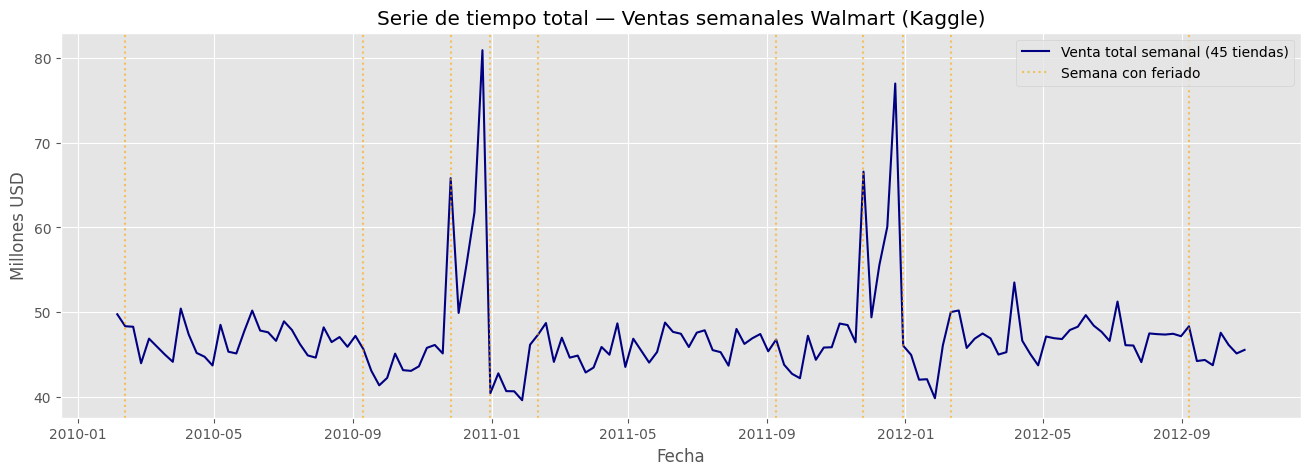

In [ ]:
df = df_spark.toPandas()
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

total = df.groupby("Date", as_index=False)["Weekly_Sales"].sum()
feriados = df[df["Holiday_Flag"] == 1]["Date"].unique()

plt.figure(figsize=(16, 5))
plt.plot(total["Date"], total["Weekly_Sales"] / 1e6, color="navy", label="Venta total semanal (45 tiendas)")
for i, f in enumerate(feriados):
    plt.axvline(f, color="orange", alpha=0.6, ls=":", label="Semana con feriado" if i == 0 else None)
plt.title("Serie de tiempo total — Ventas semanales Walmart (Kaggle)")
plt.xlabel("Fecha"); plt.ylabel("Millones USD"); plt.legend(); plt.show()

La venta total de la cadena se mantiene casi plana entre **40 y 50 millones USD** por semana, pero tiene dos picos muy marcados cada año: **Thanksgiving (~66 millones)** y sobre todo **la semana previa a Navidad (81 millones en 2010 y 77 millones en 2011)**, seguidos de una caída fuerte en enero (~40 millones). Un detalle interesante: el `Holiday_Flag` de Navidad cae en la semana del 31 de diciembre, que es justo cuando la venta ya bajó; el pico real está en la semana anterior.

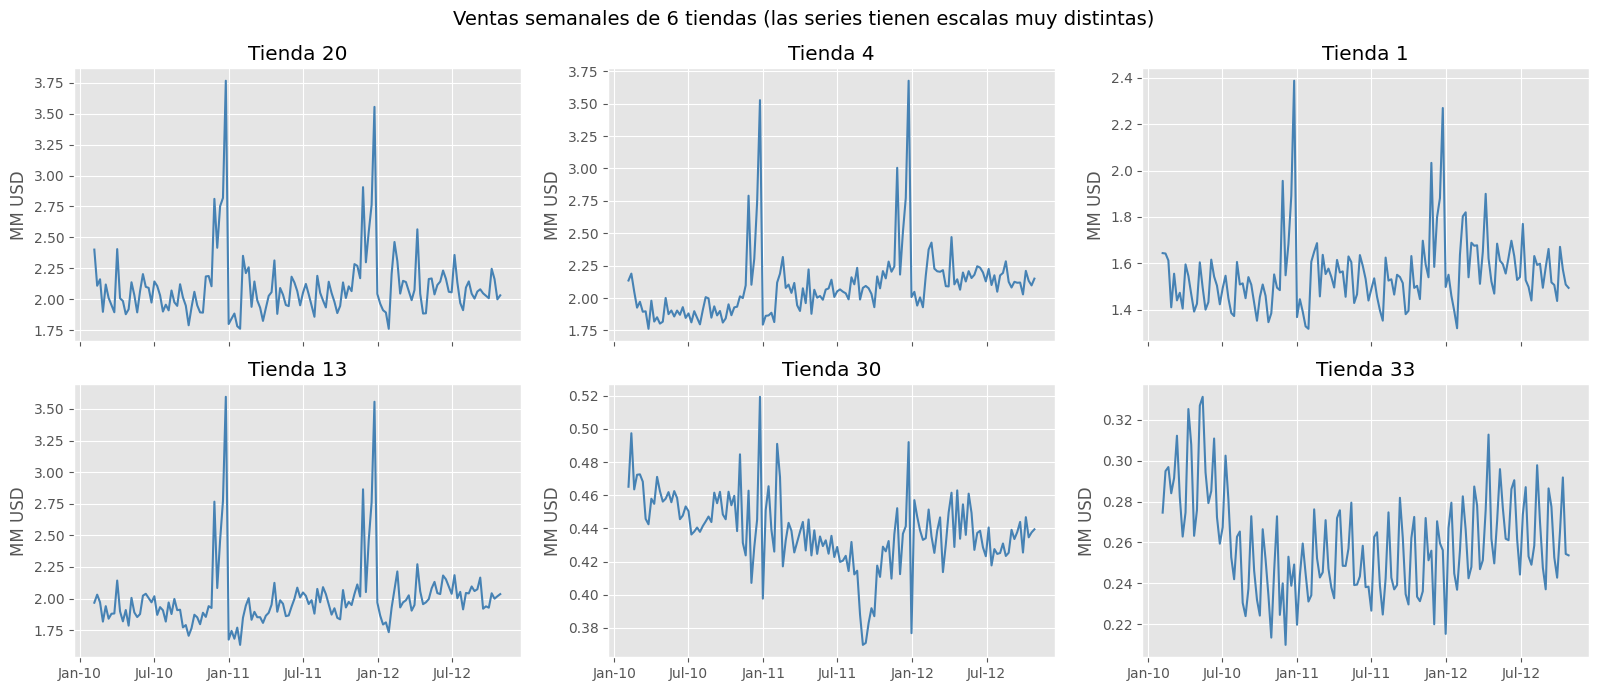

In [ ]:
# Algunas tiendas individuales para ver la diferencia de escala entre series
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for ax, s in zip(axes.ravel(), [20, 4, 1, 13, 30, 33]):
    d = df[df["Store"] == s]
    ax.plot(d["Date"], d["Weekly_Sales"] / 1e6, color="steelblue")
    ax.set_title(f"Tienda {s}"); ax.set_ylabel("MM USD")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
fig.suptitle("Ventas semanales de 6 tiendas (las series tienen escalas muy distintas)", fontsize=14)
plt.tight_layout(); plt.show()

Cada tienda es una serie con su propia escala y comportamiento: las grandes (20, 4, 13) repiten claramente los picos de fin de año, la tienda 1 es más ruidosa y las pequeñas (30, 33) casi no tienen pico navideño y muestran cambios de nivel. Este es justamente el escenario donde un modelo fundacional es útil: **un solo modelo** tiene que adaptarse a 45 series distintas.

## **3.4 Estacionalidad anual**

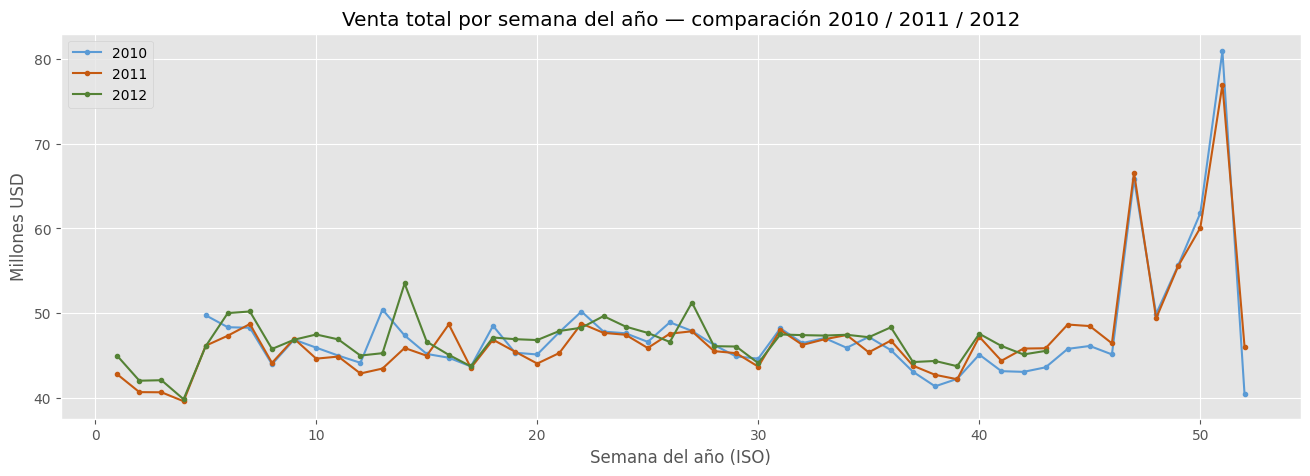

In [ ]:
total["anio"] = total["Date"].dt.year
total["semana"] = total["Date"].dt.isocalendar().week.astype(int)

plt.figure(figsize=(16, 5))
for anio, color in zip([2010, 2011, 2012], ["#5b9bd5", "#c55a11", "#548235"]):
    d = total[total["anio"] == anio]
    plt.plot(d["semana"], d["Weekly_Sales"] / 1e6, marker="o", ms=3, label=str(anio), color=color)
plt.title("Venta total por semana del año — comparación 2010 / 2011 / 2012")
plt.xlabel("Semana del año (ISO)"); plt.ylabel("Millones USD"); plt.legend(); plt.show()

Al superponer los tres años, las curvas prácticamente **coinciden semana a semana**: el patrón se repite con picos en la **semana 47 (Thanksgiving)** y la **semana 51 (Navidad)**, y el valle en las semanas 1–4. En 2012 la venta está ligeramente por encima de los años anteriores en varias semanas, lo que sugiere un pequeño crecimiento.

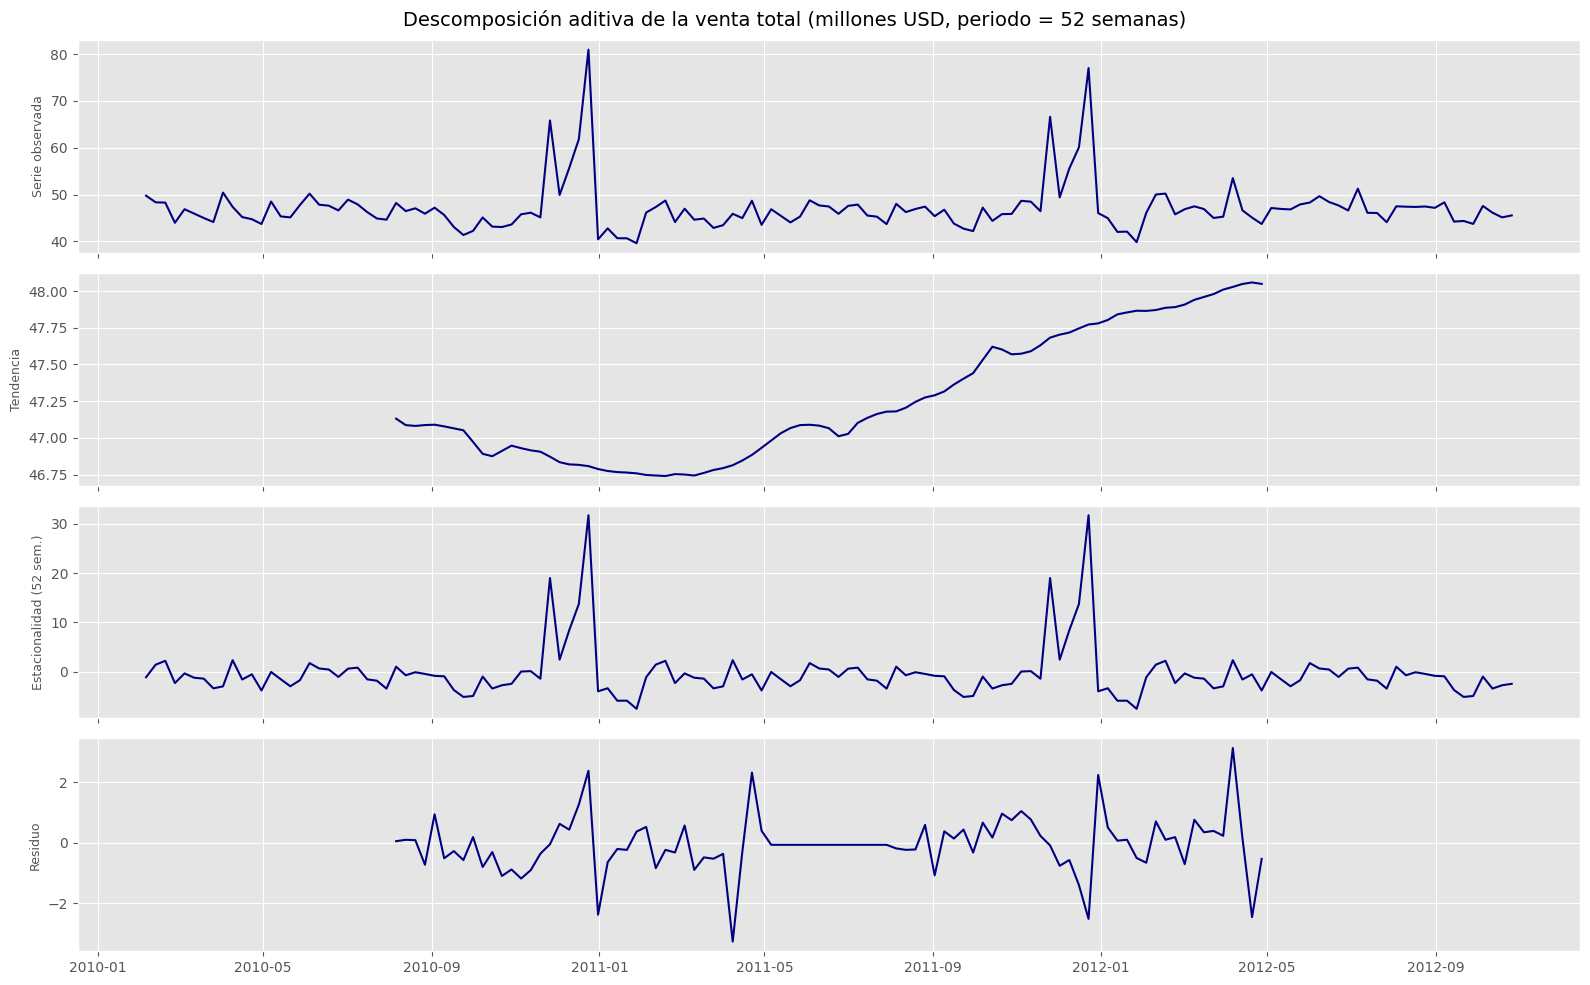

Fuerza de la estacionalidad: 0.98 | Fuerza de la tendencia: 0.25  (escala 0 a 1)


In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf

serie_total = total.set_index("Date")["Weekly_Sales"] / 1e6
desc = seasonal_decompose(serie_total, model="additive", period=52)

fig, axes = plt.subplots(4, 1, figsize=(16, 10), sharex=True)
for ax, comp, nombre in zip(axes, [serie_total, desc.trend, desc.seasonal, desc.resid],
                            ["Serie observada", "Tendencia", "Estacionalidad (52 sem.)", "Residuo"]):
    ax.plot(comp, color="navy"); ax.set_ylabel(nombre, fontsize=9)
fig.suptitle("Descomposición aditiva de la venta total (millones USD, periodo = 52 semanas)", fontsize=14)
plt.tight_layout(); plt.show()

r = desc.resid.dropna(); st = desc.seasonal[r.index]; tr_ = desc.trend[r.index]
fuerza_est = max(0, 1 - r.var() / (st + r).var())
fuerza_ten = max(0, 1 - r.var() / (tr_ + r).var())
print(f"Fuerza de la estacionalidad: {fuerza_est:.2f} | Fuerza de la tendencia: {fuerza_ten:.2f}  (escala 0 a 1)")

La descomposición lo confirma: la **tendencia** apenas se mueve de ~46.8 a ~48.0 millones (crecimiento leve de ~2.5%), mientras que la **estacionalidad anual** va de −7 a +32 millones. La fuerza de la estacionalidad es **0.98** y la de la tendencia solo **0.25**: esta serie está dominada por el patrón anual de fin de año.

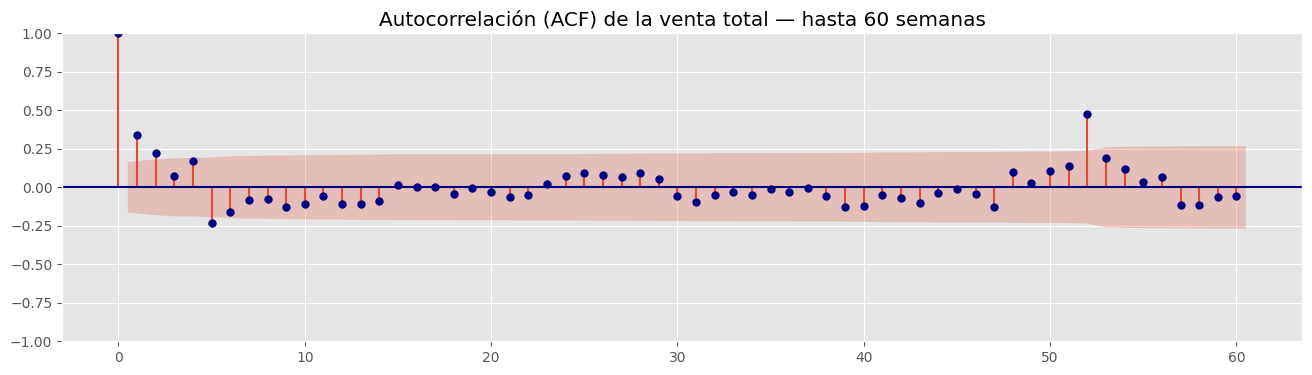

Prueba ADF -> estadístico: -5.908 | p-valor: 0.0000
Conclusión: serie estacionaria


In [ ]:
from statsmodels.tsa.stattools import adfuller

fig, ax = plt.subplots(figsize=(16, 4))
plot_acf(serie_total, lags=60, ax=ax, color="navy")
ax.set_title("Autocorrelación (ACF) de la venta total — hasta 60 semanas")
plt.show()

adf = adfuller(serie_total)
print(f"Prueba ADF -> estadístico: {adf[0]:.3f} | p-valor: {adf[1]:.4f}")
print("Conclusión:", "serie estacionaria" if adf[1] < 0.05 else "serie NO estacionaria")

En la ACF destaca la autocorrelación en el **rezago 52 (≈ 0.47)**, que es la huella de la estacionalidad anual; los rezagos 1 y 2 también son positivos pero débiles. La prueba ADF da **p-valor ≈ 0.000**, así que la serie es estacionaria en media (no hay una tendencia fuerte que diferenciar). Esto anticipa que un ARIMA no estacional va a tener problemas, porque la información clave está a 52 semanas de distancia.

## **3.5 Variables externas vs. ventas**

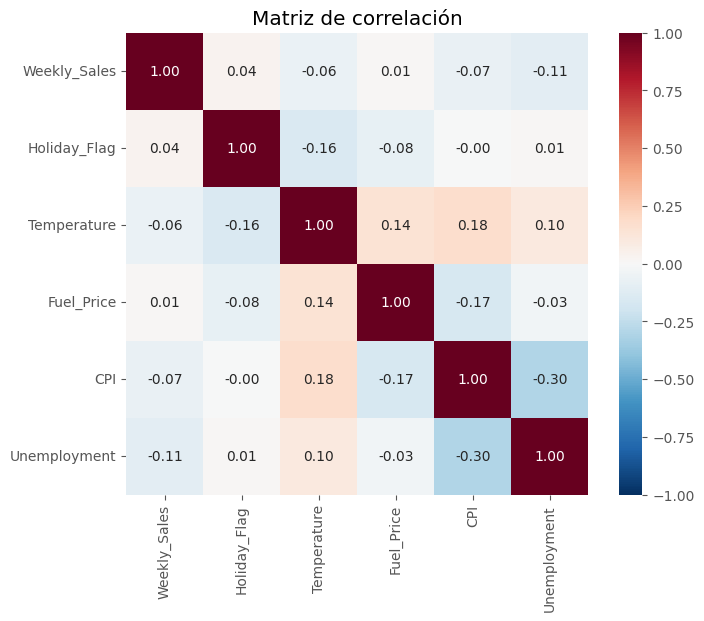

In [ ]:
corr = df[["Weekly_Sales", "Holiday_Flag", "Temperature", "Fuel_Price", "CPI", "Unemployment"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlación")
plt.show()

Las variables externas tienen correlaciones lineales **muy bajas** con la venta (todas con |r| ≤ 0.11): desempleo −0.11, CPI −0.07, temperatura −0.06 y combustible 0.01. Es decir, la venta se explica sobre todo por **su propia historia y el calendario**, lo que respalda usar un TSFM univariado como Chronos.

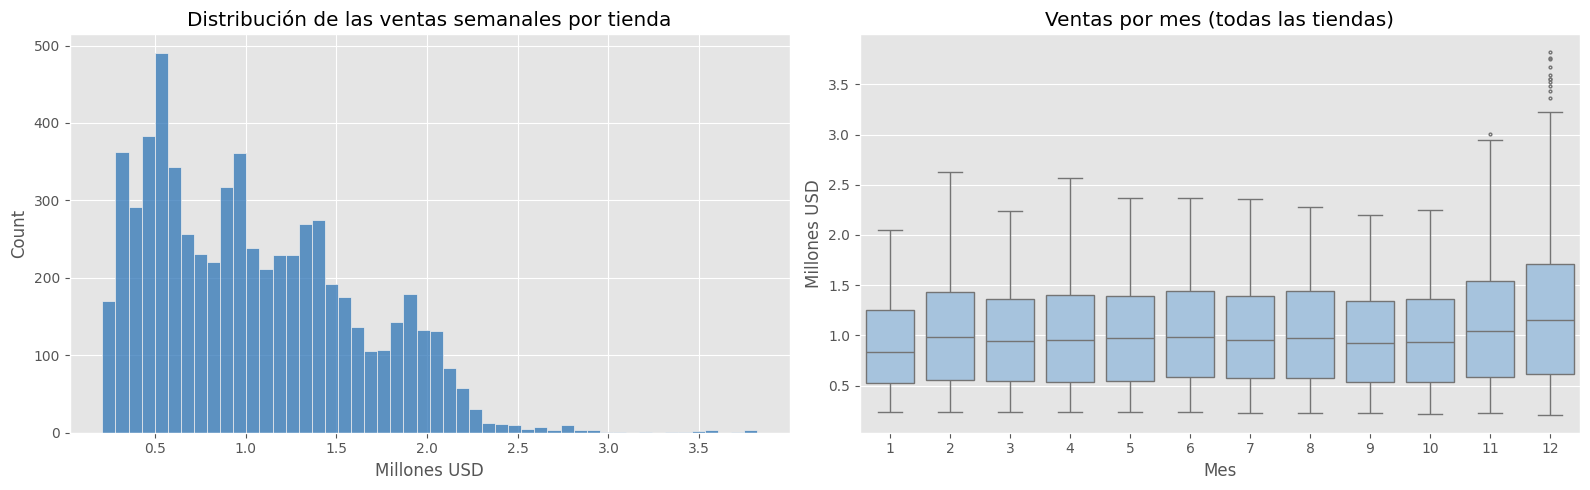

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(df["Weekly_Sales"] / 1e6, bins=50, color="#2e75b6", ax=axes[0])
axes[0].set_title("Distribución de las ventas semanales por tienda"); axes[0].set_xlabel("Millones USD")
df["mes"] = df["Date"].dt.month
sns.boxplot(data=df, x="mes", y=df["Weekly_Sales"] / 1e6, color="#9dc3e6", ax=axes[1], fliersize=2)
axes[1].set_title("Ventas por mes (todas las tiendas)"); axes[1].set_ylabel("Millones USD"); axes[1].set_xlabel("Mes")
plt.tight_layout(); plt.show()

La distribución de ventas por tienda-semana es **asimétrica a la derecha**: la mayoría está entre 0.5 y 1.5 millones y los valores extremos (más de 3 millones) aparecen solo en diciembre. En el boxplot mensual se ve que **noviembre y diciembre** tienen la mediana y la dispersión más altas, y **enero** la mediana más baja.

### **Hallazgos del EDA que guían el modelado**

* Datos **completos y limpios**: 45 series semanales sin huecos, 143 semanas cada una.
* La demanda es **muy estable durante el año** y el gran reto son los **picos de Thanksgiving y Navidad** (estacionalidad anual, rezago 52).
* Las tiendas tienen **escalas muy distintas** → hay que usar métricas porcentuales y un modelo que normalice cada serie.
* Las variables macro (CPI, combustible, desempleo, temperatura) casi no se relacionan linealmente con la venta, un modelo **univariado** es razonable.
* Solo hay **~2.5 años de historia**: muy poco para modelos clásicos estacionales (SARIMA con periodo 52), lo que hace atractivo un modelo **preentrenado** que ya trae conocimiento de miles de otras series.
* Horizonte elegido: **12 semanas**, evaluado primero en ago–oct 2012 y luego con *backtesting* que incluye la Navidad 2011.

# <font color=orange>**4.- Modelado: Chronos-Bolt (Amazon) vía Hugging Face**</font>

## **4.1 ¿Qué es Chronos y por qué lo elegimos?**

**Chronos** es la familia de modelos fundacionales de series de tiempo de **Amazon Science** (2024). La versión **Chronos-Bolt** (nov. 2024) es la evolución rápida: hasta **250 veces más rápida** y **20 veces más eficiente en memoria** que el Chronos original, y además más precisa. Está publicada gratis en Hugging Face (`amazon/chronos-bolt-small`, licencia Apache 2.0).

Lo elegimos frente a otras opciones (TimesFM, MOIRAI, Lag-Llama, Granite TTM) porque:
* Es de los TSFM mejor posicionados en benchmarks zero-shot (GIFT-Eval, benchmark de 27 datasets del paper de Chronos).
* Corre sin problemas en Colab gratis, incluso sin GPU.
* Entrega **cuantiles** (p10…p90) de forma nativa, intervalos de incertidumbre para decidir inventario de seguridad.
* Acepta un **lote de series** en una sola llamada: las 45 tiendas de golpe.



| Modelo | Empresa | Arquitectura | Tokenización | Salida |
|---|---|---|---|---|
| TimesFM | Google | Transformer solo-decodificador | Parches | Media + cuantiles |
| Lag-Llama | ServiceNow/Mila | Transformer decodificador (tipo LLaMA) | Lags como features | Distribución t-Student |
| MOIRAI | Salesforce | Transformer encoder (masked) | Parches multi-tamaño | Mezcla de distribuciones |
| Granite TTM | IBM | **TSMixer** (MLP-Mixer, sin atención) | Parches | Puntual |
| **Chronos (original)** | Amazon | **Transformer encoder-decoder T5** | **Escalado + cuantización en 4096 "palabras"** | Muestras (como un LLM) |
| **Chronos-Bolt** | Amazon | **Transformer encoder-decoder T5** | **Normalización + parches de 16 puntos** | **9 cuantiles directos, multi-paso** |

## **4.2 Arquitectura: Transformer encoder-decoder (T5)**

Chronos-Bolt reutiliza la arquitectura **T5** de Google (la misma idea de los LLMs) pero adaptada a números:

1. **Normalización por instancia:** cada serie se estandariza con su propia media y desviación `(x − μ) / σ`. Así una tienda que vende 2 millones y otra que vende 300 mil "se ven" iguales para el modelo.
>
2. **Patching (tokenización):** la serie normalizada se corta en **parches de 16 semanas consecutivas**. Cada parche es un "token", igual que una palabra en un LLM o un bloque de píxeles en un Vision Transformer.
>
3. **Embedding de parches:** un bloque residual (MLP) convierte cada parche (16 valores + 16 de máscara) en un vector de 512 dimensiones. Se agrega un token especial `[REG]` al final.
>
4. **Encoder (6 capas de self-attention, 8 cabezas):** cada parche "mira" a todos los demás a la vez; la atención aprende qué momentos del pasado importan más (por ejemplo, el mismo trimestre del año anterior). Esto evita el "olvido" de largo plazo de las LSTM.
>
5. **Decoder + cabeza de cuantiles:** en lugar de generar token por token como Chronos original, el decoder produce **de una sola vez** los 9 cuantiles (0.1 … 0.9) para los próximos 64 pasos (*direct multi-step forecasting*). Se entrena con **pérdida de cuantiles (pinball loss)**.

>
6. **Des-normalización:** los cuantiles se regresan a la escala original (USD) con la μ y σ de cada serie.

> **Chronos original vs Chronos-Bolt:** el Chronos original tokenizaba de forma distinta: dividía la serie entre su media absoluta y luego **cuantizaba** cada valor en uno de **4,096 bins** (como un vocabulario de palabras), prediciendo el siguiente "token" con entropía cruzada, igual que un LLM. Chronos-Bolt reemplazó eso por parches continuos, que es mucho más rápido.

## **4.3 División Train (contexto) / Test**

A Chronos no se le "entrena": se le pasa el **contexto** (historia) y genera el pronóstico. Reservamos las **últimas 12 semanas** (03/08/2012 a 26/10/2012) como Test para todas las tiendas, igual que haríamos con cualquier otro modelo.

In [ ]:
HORIZONTE = 12                                   # 12 semanas ≈ 1 trimestre
fecha_corte = df["Date"].max() - pd.Timedelta(weeks=HORIZONTE)

train_df = df[df["Date"] <= fecha_corte].copy()
test_df  = df[df["Date"] >  fecha_corte].copy()
TIENDAS = sorted(df["Store"].unique())

print(f"Fecha de corte : {fecha_corte.date()}")
print(f"Train (contexto): {train_df['Date'].min().date()} -> {train_df['Date'].max().date()} | {train_df['Date'].nunique()} semanas x {len(TIENDAS)} tiendas = {len(train_df)} filas")
print(f"Test (horizonte): {test_df['Date'].min().date()} -> {test_df['Date'].max().date()} | {test_df['Date'].nunique()} semanas x {len(TIENDAS)} tiendas = {len(test_df)} filas")

# Matriz de valores reales del test: (45 tiendas x 12 semanas)
Y_test = np.array([test_df.loc[test_df["Store"] == s, "Weekly_Sales"].values for s in TIENDAS])
fechas_test = np.sort(test_df["Date"].unique())
Y_test.shape

Fecha de corte : 2012-08-03
Train (contexto): 2010-02-05 -> 2012-08-03 | 131 semanas x 45 tiendas = 5895 filas
Test (horizonte): 2012-08-10 -> 2012-10-26 | 12 semanas x 45 tiendas = 540 filas


(45, 12)

## **4.4 Carga del modelo desde Hugging Face**

In [ ]:
%%time
import torch
from chronos import BaseChronosPipeline

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

pipeline = BaseChronosPipeline.from_pretrained(
    "amazon/chronos-bolt-small",      # modelo oficial en Hugging Face (Apache 2.0)
    device_map=DEVICE,
    torch_dtype=torch.float32,
)

modelo = pipeline.model
cfg = modelo.config
n_params = sum(p.numel() for p in modelo.parameters())
print(f"Dispositivo: {DEVICE}")
print(f"Clase del pipeline: {type(pipeline).__name__}")
print(f"Parámetros: {n_params/1e6:.1f} millones")
print(f"Arquitectura base: {cfg.model_type.upper()} encoder-decoder | capas encoder={cfg.num_layers}, decoder={cfg.num_decoder_layers}, "
      f"cabezas de atención={cfg.num_heads}, d_model={cfg.d_model}")
print("Configuración Chronos:", cfg.chronos_config)

Dispositivo: cuda
Clase del pipeline: ChronosBoltPipeline
Parámetros: 47.7 millones
Arquitectura base: T5 encoder-decoder | capas encoder=6, decoder=6, cabezas de atención=8, d_model=512
Configuración Chronos: {'context_length': 2048, 'input_patch_size': 16, 'input_patch_stride': 16, 'prediction_length': 64, 'quantiles': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], 'use_reg_token': True}
CPU times: user 15.3 s, sys: 2.22 s, total: 17.6 s
Wall time: 34.1 s


El modelo se descargó de Hugging Face en pocos segundos. Chronos-Bolt Small tiene **47.7 millones de parámetros** con arquitectura **T5 encoder-decoder** (6 capas en el encoder, 6 en el decoder, 8 cabezas de atención y vectores de 512 dimensiones). En la configuración se ven las piezas clave: parches de **16** puntos (`input_patch_size`), un contexto máximo de **2,048** pasos (nuestras 131 semanas entran completas), **64** pasos de predicción por pasada (nuestras 12 semanas salen en una sola pasada) y los **9 cuantiles** de salida.

## **4.5 Tokenización de la serie paso a paso (dentro del modelo real)**

Para no quedarnos solo en teoría, usamos **los mismos módulos internos del modelo** (`instance_norm`, `patch` e `input_patch_embedding`) sobre la serie de la **Tienda 1** para ver cómo Chronos-Bolt convierte los números en tokens.

In [ ]:
serie_t1 = torch.tensor(train_df.loc[train_df["Store"] == 1, "Weekly_Sales"].values, dtype=torch.float32).unsqueeze(0)

with torch.no_grad():
    # Paso 1: normalización por instancia  (x - media) / desviación
    serie_norm, (loc, scale) = modelo.instance_norm(serie_t1.to(modelo.device))
    # Paso 2: patching -> parches de 16 semanas (se rellena con NaN a la izquierda si no calza exacto)
    parches = modelo.patch(serie_norm)
    mascara = modelo.patch(torch.ones_like(serie_norm))
    # Paso 3: embedding de cada parche (valores + máscara) a un vector de 512 dimensiones
    entrada = torch.cat([torch.nan_to_num(parches, nan=0.0), torch.nan_to_num(mascara, nan=0.0)], dim=-1)
    tokens = modelo.input_patch_embedding(entrada)

print(f"Serie original      : {tuple(serie_t1.shape)}  -> {serie_t1.shape[1]} semanas")
print(f"Media / desviación  : {loc.item():,.0f} / {scale.item():,.0f} USD")
print(f"Parches (tokens)    : {tuple(parches.shape)} -> {parches.shape[1]} tokens de {parches.shape[2]} semanas")
print(f"Semanas de relleno  : {int(torch.isnan(parches).sum())} (NaN a la izquierda del primer parche)")
print(f"Embeddings          : {tuple(tokens.shape)} -> cada token es un vector de {tokens.shape[2]} dimensiones")
print(f"+ 1 token [REG] al final -> el encoder recibe {tokens.shape[1] + 1} tokens")

Serie original      : (1, 131)  -> 131 semanas
Media / desviación  : 1,555,484 / 161,064 USD
Parches (tokens)    : (1, 9, 16) -> 9 tokens de 16 semanas
Semanas de relleno  : 13 (NaN a la izquierda del primer parche)
Embeddings          : (1, 9, 512) -> cada token es un vector de 512 dimensiones
+ 1 token [REG] al final -> el encoder recibe 10 tokens


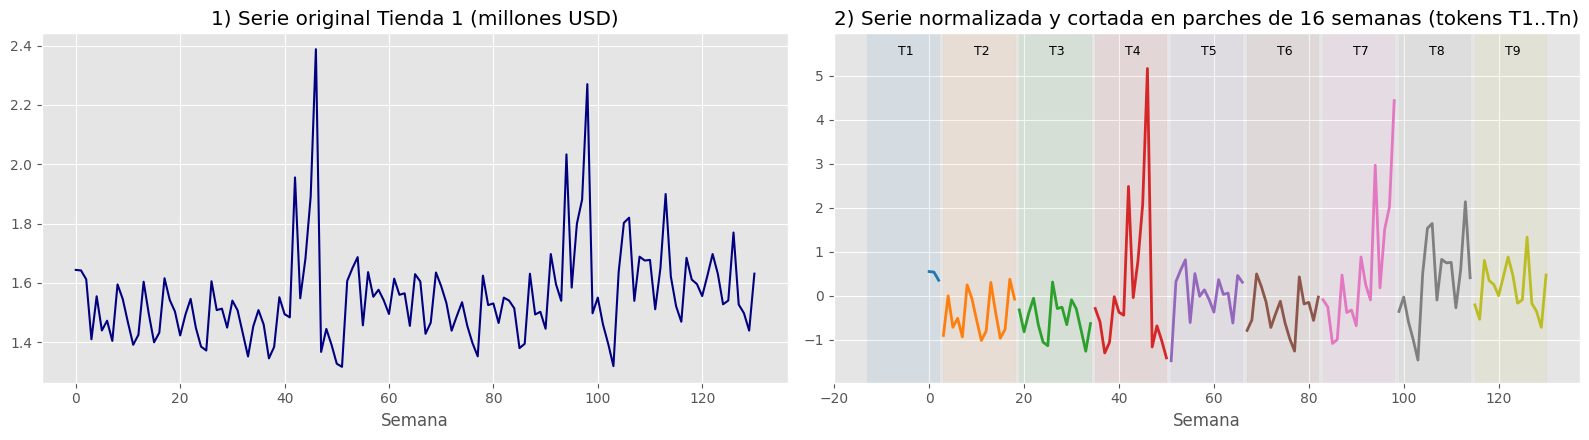

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
x_orig = serie_t1.squeeze().numpy()
axes[0].plot(x_orig / 1e6, color="navy")
axes[0].set_title("1) Serie original Tienda 1 (millones USD)"); axes[0].set_xlabel("Semana")

p = parches.squeeze(0).cpu().numpy()
colores = plt.cm.tab10(np.arange(p.shape[0]) % 10)
inicio = -int(np.isnan(p).sum())
for i, fila in enumerate(p):
    idx = np.arange(i * 16, (i + 1) * 16) + inicio
    axes[1].plot(idx, fila, color=colores[i], lw=2)
    axes[1].axvspan(idx[0], idx[-1], color=colores[i], alpha=0.08)
    axes[1].text(idx[0] + 8, np.nanmax(p) + 0.3, f"T{i+1}", ha="center", fontsize=9)
axes[1].set_title("2) Serie normalizada y cortada en parches de 16 semanas (tokens T1..Tn)")
axes[1].set_xlabel("Semana"); axes[1].set_ylim(np.nanmin(p) - 0.5, np.nanmax(p) + 0.8)
plt.tight_layout(); plt.show()

Así "ve" Chronos a la Tienda 1: primero la normaliza con su media (**1.56 millones**) y desviación (**161 mil**), y luego corta las 131 semanas en **9 parches de 16 semanas**; como 131 no es múltiplo de 16, rellena **13 semanas con NaN** al inicio (por eso el token T1 casi está vacío). Cada parche se convierte en un vector de **512 dimensiones** y se agrega el token `[REG]`, así que el encoder trabaja con solo **10 tokens** en lugar de 131 números. En el gráfico se ve que los tokens **T4 y T7** contienen los picos navideños (llegan a +5 desviaciones): la atención puede relacionar directamente esos dos tokens.

**Comparación con la tokenización del Chronos original (cuantización en 4,096 bins).** A modo ilustrativo replicamos la idea del Chronos original: escalar por la media absoluta y asignar cada valor a un "bin" (una palabra del vocabulario):

In [ ]:
# Tokenización estilo Chronos original: mean scaling + cuantización uniforme en 4096 bins entre -15 y 15
N_BINS, LIM = 4096, 15.0
x = serie_t1.squeeze().numpy()
escala = np.mean(np.abs(x))
x_escalada = x / escala
bordes = np.linspace(-LIM, LIM, N_BINS + 1)
tokens_id = np.digitize(x_escalada, bordes)          # id de "palabra" para cada semana
reconstruida = (bordes[tokens_id - 1] + bordes[tokens_id]) / 2 * escala

demo = pd.DataFrame({"Semana": np.arange(1, 9), "Venta real": x[:8], "Valor escalado": x_escalada[:8],
                     "Token ID": tokens_id[:8], "Venta reconstruida": reconstruida[:8]})
print(f"Escala (media absoluta): {escala:,.0f} USD  |  error máx. de reconstrucción: {np.max(np.abs(x - reconstruida)):,.0f} USD")
demo

Escala (media absoluta): 1,555,484 USD  |  error máx. de reconstrucción: 5,686 USD


,Semana,Venta real,Valor escalado,Token ID,Venta reconstruida
0,1,"1,643,690.88",1.06,2193,"1,646,245.49"
1,2,"1,641,957.50",1.06,2193,"1,646,245.49"
2,3,"1,611,968.12",1.04,2190,"1,612,067.38"
3,4,"1,409,727.62",0.91,2172,"1,406,998.74"
4,5,"1,554,806.62",1.00,2185,"1,555,103.87"
5,6,"1,439,541.62",0.93,2175,"1,441,176.84"
6,7,"1,472,515.75",0.95,2178,"1,475,354.95"
7,8,"1,404,429.88",0.90,2172,"1,406,998.74"


Con la tokenización del Chronos original, cada semana se vuelve un **número entero entre 1 y 4,096** (aquí entre 2,172 y 2,193, porque las ventas están cerca de su media). Al reconstruir desde el token el error máximo es de **≈ 5,700 USD (~0.4%)**, o sea que la cuantización casi no pierde información. La diferencia es que así el modelo necesita **un token por semana** (131 tokens) y Chronos-Bolt con parches solo usa 10: por eso Bolt es mucho más rápido.

## **4.6 Pronóstico Zero-Shot de las 45 tiendas**

Le pasamos al modelo una **lista con las 45 series de contexto** y pedimos 12 semanas. **No hay `.fit()`**: una sola llamada a `predict_quantiles` genera la mediana (p50) y la banda p10–p90 de todas las tiendas.

In [ ]:
%%time
contextos = [torch.tensor(train_df.loc[train_df["Store"] == s, "Weekly_Sales"].values, dtype=torch.float32)
             for s in TIENDAS]

t0 = time.time()
cuantiles, media = pipeline.predict_quantiles(
    inputs=contextos,
    prediction_length=HORIZONTE,
    quantile_levels=[0.1, 0.5, 0.9],
)
tiempo_chronos = time.time() - t0

pred_chronos = cuantiles[:, :, 1].numpy()     # mediana (p50) -> pronóstico puntual
p10_chronos  = cuantiles[:, :, 0].numpy()
p90_chronos  = cuantiles[:, :, 2].numpy()

print("Forma de la salida de cuantiles:", tuple(cuantiles.shape), "-> (tiendas, semanas, cuantiles)")
print(f"Tiempo de inferencia para 45 tiendas: {tiempo_chronos:.2f} s")

Forma de la salida de cuantiles: (45, 12, 3) -> (tiendas, semanas, cuantiles)
Tiempo de inferencia para 45 tiendas: 0.46 s
CPU times: user 133 ms, sys: 90.2 ms, total: 223 ms
Wall time: 482 ms


In [ ]:
# Vista del pronóstico de la Tienda 1 frente a lo real
i = TIENDAS.index(1)
pd.DataFrame({"Fecha": pd.to_datetime(fechas_test).date, "Real": Y_test[i], "p10": p10_chronos[i],
              "Pronóstico p50": pred_chronos[i], "p90": p90_chronos[i]})

,Fecha,Real,p10,Pronóstico p50,p90
0,2012-08-10,"1,592,409.97","1,519,272.50","1,606,978.50","1,753,452.88"
1,2012-08-17,"1,597,868.05","1,465,013.62","1,561,322.75","1,715,590.25"
2,2012-08-24,"1,494,122.38","1,411,823.62","1,524,642.12","1,677,392.38"
3,2012-08-31,"1,582,083.40","1,451,024.12","1,575,893.00","1,739,491.38"
4,2012-09-07,"1,661,767.33","1,489,350.88","1,618,817.25","1,804,635.25"
5,2012-09-14,"1,517,428.87","1,455,624.25","1,591,864.00","1,793,134.88"
6,2012-09-21,"1,506,126.06","1,405,204.00","1,539,111.50","1,747,316.50"
7,2012-09-28,"1,437,059.26","1,422,581.00","1,550,552.75","1,759,896.75"
8,2012-10-05,"1,670,785.97","1,460,663.50","1,581,895.88","1,809,874.00"
9,2012-10-12,"1,573,072.81","1,432,121.88","1,559,986.12","1,803,325.25"


Para la Tienda 1, el pronóstico p50 queda muy cerca de lo real (por ejemplo, 1.61 millones pronosticados vs 1.59 millones reales la primera semana) y **las 12 semanas reales caen dentro del intervalo p10–p90**.

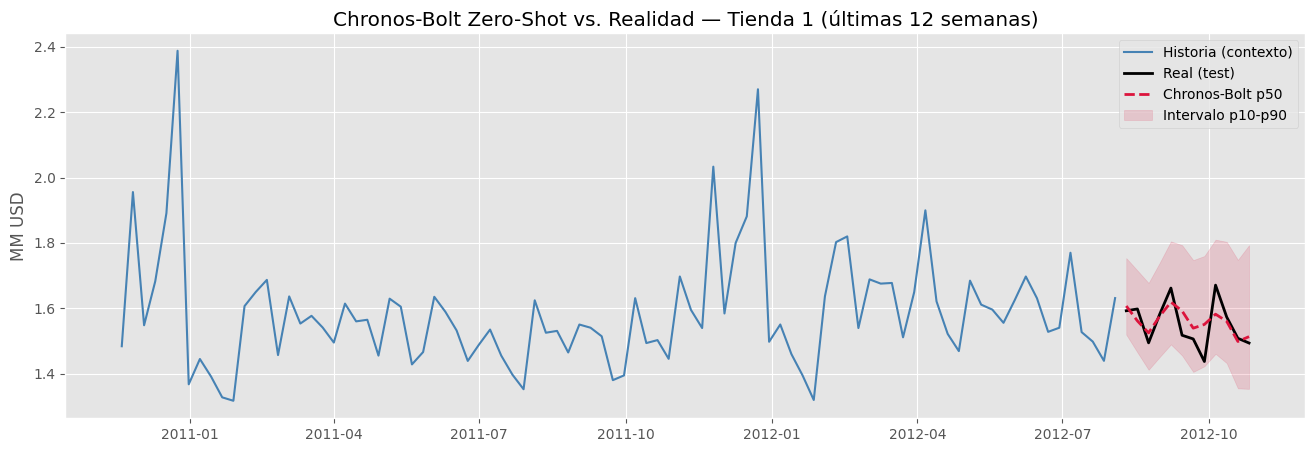

In [ ]:
def graficar_tienda(s, ax, semanas_hist=52):
    i = TIENDAS.index(s)
    h = train_df[train_df["Store"] == s].tail(semanas_hist)
    ax.plot(h["Date"], h["Weekly_Sales"] / 1e6, color="steelblue", label="Historia (contexto)")
    ax.plot(fechas_test, Y_test[i] / 1e6, color="black", lw=2, label="Real (test)")
    ax.plot(fechas_test, pred_chronos[i] / 1e6, color="crimson", ls="--", lw=2, label="Chronos-Bolt p50")
    ax.fill_between(fechas_test, p10_chronos[i] / 1e6, p90_chronos[i] / 1e6, color="crimson", alpha=0.15, label="Intervalo p10-p90")
    ax.set_title(f"Tienda {s}"); ax.set_ylabel("MM USD")

fig, ax = plt.subplots(figsize=(16, 5))
graficar_tienda(1, ax, semanas_hist=90)
ax.set_title("Chronos-Bolt Zero-Shot vs. Realidad — Tienda 1 (últimas 12 semanas)")
ax.legend(); plt.show()

El gráfico muestra que Chronos captó el **nivel** de la tienda y generó un pronóstico suave que sigue bien a la línea real. No reproduce cada subida puntual (por ejemplo la del 5 de octubre), pero esas semanas quedan dentro de la banda de incertidumbre, que es justamente para lo que sirve.

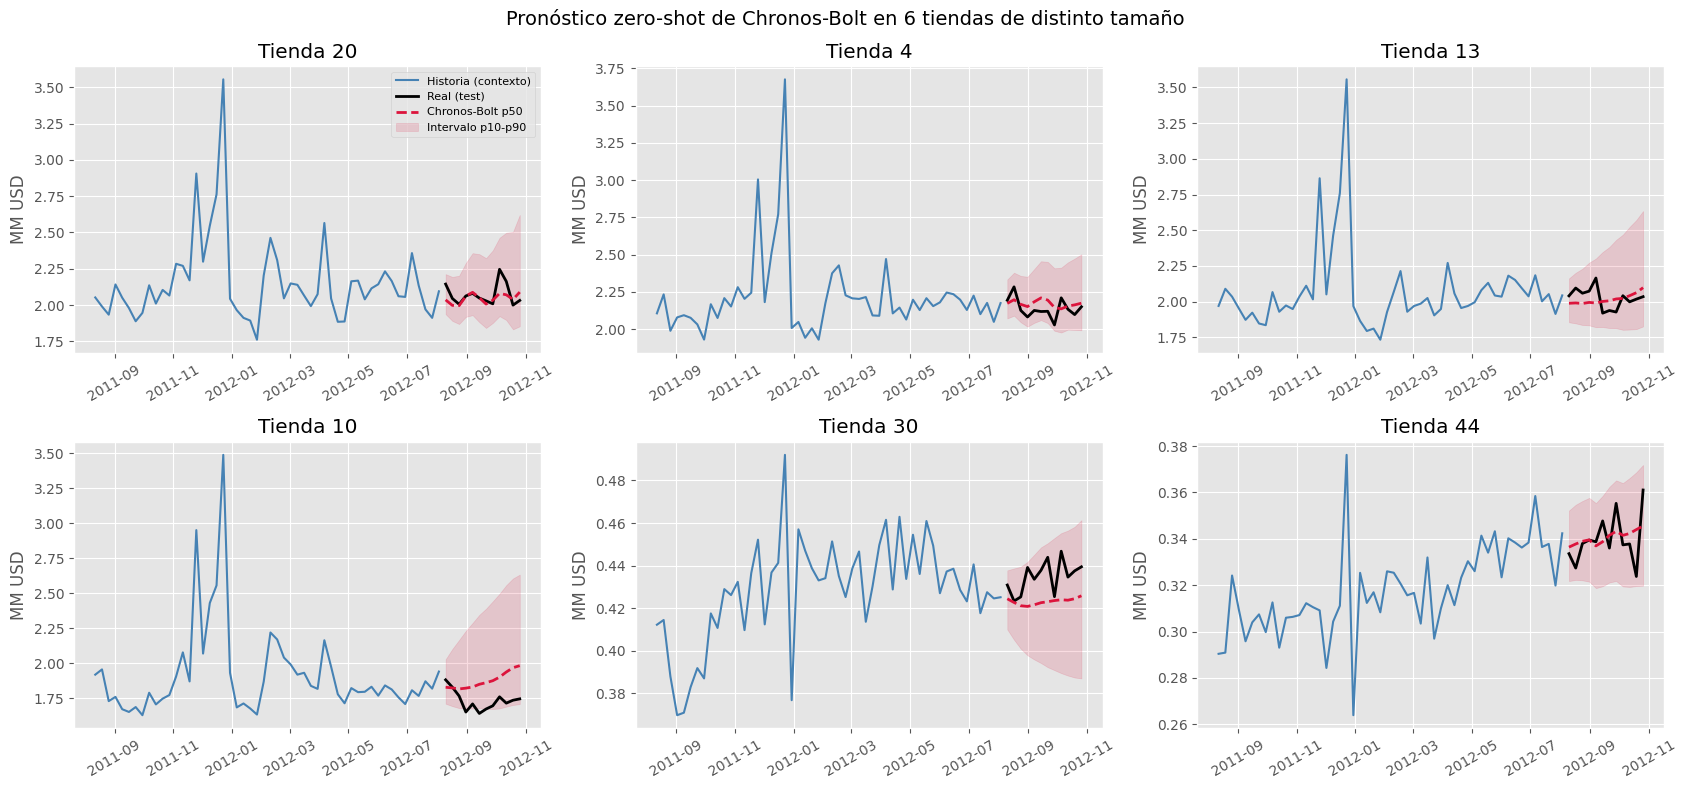

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, s in zip(axes.ravel(), [20, 4, 13, 10, 30, 44]):
    graficar_tienda(s, ax)
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Pronóstico zero-shot de Chronos-Bolt en 6 tiendas de distinto tamaño", fontsize=14)
plt.tight_layout(); plt.show()

En tiendas grandes y estables (20, 4, 44) el pronóstico se pega mucho a lo real. En la **tienda 10** el modelo extrapoló la subida de las semanas previas y **sobreestimó** la demanda, y en la **tienda 30** subestimó un poco, aunque lo real quedó dentro de la banda. También se ve que la **banda p10–p90 se ensancha** conforme avanza el horizonte: el modelo reconoce que a 12 semanas hay más incertidumbre.

# <font color=orange>**5.- Evaluación**</font>

## **5.1 ¿Cómo medimos la efectividad?**

* **MAE** (Error Absoluto Medio): error promedio en USD por tienda-semana.
* **RMSE** (Raíz del Error Cuadrático Medio): penaliza más los errores grandes (picos no anticipados).
* **MAPE** (Error Porcentual Absoluto Medio): error promedio en %, independiente de la escala.
* **WAPE** (Error Porcentual Absoluto Ponderado) = Σ|real − pred| / Σ real: es la métrica estándar en retail porque pondera por volumen (equivocarse en una tienda grande pesa más).
* **Cobertura p10–p90:** % de semanas reales que caen dentro del intervalo; si el intervalo está bien calibrado debería rondar el **80%**.

Comparamos Chronos contra: **Naive** (repite la última semana), **Naive estacional** (misma semana del año anterior), **Auto-ARIMA**, **Prophet** (Meta, con feriados de EE.UU.) y **XGBoost** (global, con *lags* y calendario).

In [ ]:
def metricas(y_real, y_pred):
    y_real, y_pred = np.asarray(y_real).ravel(), np.asarray(y_pred).ravel()
    return {
        "MAE": float(mean_absolute_error(y_real, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred))),
        "MAPE (%)": float(np.mean(np.abs((y_real - y_pred) / y_real)) * 100),
        "WAPE (%)": float(np.sum(np.abs(y_real - y_pred)) / np.sum(y_real) * 100),
    }

m_chronos = metricas(Y_test, pred_chronos)
cobertura = np.mean((Y_test >= p10_chronos) & (Y_test <= p90_chronos)) * 100

print("=== EVALUACIÓN CHRONOS-BOLT (ZERO-SHOT, 45 tiendas x 12 semanas) ===")
for k, v in m_chronos.items():
    print(f"{k:9}: {v:,.2f}" + (" USD" if k in ("MAE", "RMSE") else ""))
print(f"Cobertura del intervalo p10-p90: {cobertura:.1f}%  (ideal ≈ 80%)")

=== EVALUACIÓN CHRONOS-BOLT (ZERO-SHOT, 45 tiendas x 12 semanas) ===
MAE      : 47,299.69 USD
RMSE     : 69,108.89 USD
MAPE (%) : 4.49
WAPE (%) : 4.61
Cobertura del intervalo p10-p90: 95.4%  (ideal ≈ 80%)


Sin ningún entrenamiento, Chronos-Bolt logra un **WAPE de 4.61%** y un **MAPE de 4.49%**, es decir, un pronóstico **muy preciso** según la tabla de interpretación (< 10%). En dinero, se equivoca en promedio **≈ 47 mil USD** por tienda-semana sobre ventas de ~1 millón. La cobertura del intervalo p10–p90 es **95.4%**, mayor al 80% ideal: en un periodo tranquilo como ago–oct las bandas son algo **conservadoras (anchas)**, lo cual es preferible a quedarse corto.

**Guía rápida de interpretación del MAPE / WAPE:**

| Error | Interpretación |
|---|---|
| < 10% | Pronóstico muy preciso |
| 10% – 20% | Pronóstico bueno |
| 20% – 50% | Pronóstico razonable |
| > 50% | Pronóstico impreciso |

## **5.2 Modelos Baseline: Naive y Naive Estacional**

In [ ]:
# Naive: cada semana futura = última semana conocida
pred_naive = np.array([np.repeat(train_df.loc[train_df["Store"] == s, "Weekly_Sales"].values[-1], HORIZONTE) for s in TIENDAS])

# Naive estacional: cada semana futura = la misma semana del año anterior (52 semanas atrás)
pred_snaive = np.array([df.loc[df["Store"] == s, "Weekly_Sales"].values[-HORIZONTE - 52:-52] for s in TIENDAS])

print("Naive           :", {k: round(v, 2) for k, v in metricas(Y_test, pred_naive).items()})
print("Naive estacional:", {k: round(v, 2) for k, v in metricas(Y_test, pred_snaive).items()})

Naive           : {'MAE': 59239.97, 'RMSE': 85346.23, 'MAPE (%)': 6.01, 'WAPE (%)': 5.77}
Naive estacional: {'MAE': 53768.95, 'RMSE': 85365.67, 'MAPE (%)': 5.46, 'WAPE (%)': 5.24}


## **5.3 Modelo tradicional 1: Auto-ARIMA (un modelo por tienda)**

Usamos `pmdarima.auto_arima` para buscar el mejor `(p, d, q)` de **cada** tienda. Con solo ~2.5 años de historia semanal no alcanza para un SARIMA con periodo 52, así que usamos la versión no estacional.

In [ ]:
%%time
from pmdarima import auto_arima

t0 = time.time()
pred_arima, ordenes = [], []
for s in TIENDAS:
    y = train_df.loc[train_df["Store"] == s, "Weekly_Sales"].values
    m = auto_arima(y, seasonal=False, stepwise=True, suppress_warnings=True, error_action="ignore")
    pred_arima.append(m.predict(n_periods=HORIZONTE))
    ordenes.append(m.order)
pred_arima = np.array(pred_arima)
tiempo_arima = time.time() - t0

print("Órdenes (p,d,q) más frecuentes:", pd.Series(ordenes).value_counts().head(3).to_dict())
print("Auto-ARIMA:", {k: round(v, 2) for k, v in metricas(Y_test, pred_arima).items()})

Órdenes (p,d,q) más frecuentes: {(1, 0, 0): 14, (0, 0, 4): 5, (5, 1, 1): 4}
Auto-ARIMA: {'MAE': 61385.14, 'RMSE': 90751.13, 'MAPE (%)': 5.97, 'WAPE (%)': 5.98}
CPU times: user 3min 50s, sys: 493 ms, total: 3min 51s
Wall time: 2min 11s


## **5.4 Modelo tradicional 2: Prophet (Meta) con feriados de EE.UU.**

In [ ]:
%%time
from prophet import Prophet

def pronostico_prophet(datos, horizonte):
    salida = []
    for s in TIENDAS:
        d = datos.loc[datos["Store"] == s, ["Date", "Weekly_Sales"]].rename(columns={"Date": "ds", "Weekly_Sales": "y"})
        m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
        m.add_country_holidays(country_name="US")
        m.fit(d)
        futuro = m.make_future_dataframe(periods=horizonte, freq="W-FRI")
        salida.append(m.predict(futuro)["yhat"].values[-horizonte:])
    return np.array(salida)

t0 = time.time()
pred_prophet = pronostico_prophet(train_df, HORIZONTE)
tiempo_prophet = time.time() - t0
print("Prophet:", {k: round(v, 2) for k, v in metricas(Y_test, pred_prophet).items()})

Prophet: {'MAE': 40579.08, 'RMSE': 59058.82, 'MAPE (%)': 4.23, 'WAPE (%)': 3.95}
CPU times: user 8.63 s, sys: 371 ms, total: 9 s
Wall time: 9.98 s


## **5.5 Modelo tradicional 3: XGBoost global con *feature engineering***

Un solo modelo XGBoost para las 45 tiendas. Para que la comparación sea justa con un horizonte de 12 semanas, **solo usamos rezagos (lags) de 12 semanas o más** (valores que sí se conocen al momento de pronosticar), más calendario, tienda y la marca de feriado (que se conoce con anticipación). No usamos temperatura, combustible, CPI ni desempleo del futuro porque en producción no se conocen.

In [ ]:
def crear_features(datos):
    f = datos.sort_values(["Store", "Date"]).copy()
    g = f.groupby("Store")["Weekly_Sales"]
    for L in [12, 13, 26, 52]:
        f[f"lag_{L}"] = g.shift(L)
    f["media_movil_8_lag12"] = g.transform(lambda x: x.shift(12).rolling(8).mean())
    f["semana_anio"] = f["Date"].dt.isocalendar().week.astype(int)
    f["mes"] = f["Date"].dt.month
    return f

FEATURES = ["Store", "Holiday_Flag", "semana_anio", "mes", "lag_12", "lag_13", "lag_26", "lag_52", "media_movil_8_lag12"]
feat_df = crear_features(df)
feat_df.loc[feat_df["Store"] == 1, ["Date", "Weekly_Sales"] + FEATURES].tail(3)

,Date,Weekly_Sales,Store,Holiday_Flag,semana_anio,mes,lag_12,lag_13,lag_26,lag_52,media_movil_8_lag12
140,2012-10-12,"1,573,072.81",1,0,41,10,"1,497,954.76","1,527,014.04","1,621,031.70","1,493,525.93","1,601,925.72"
141,2012-10-19,"1,508,068.77",1,0,42,10,"1,439,123.71","1,497,954.76","1,521,577.87","1,502,562.78","1,578,756.49"
142,2012-10-26,"1,493,659.74",1,0,43,10,"1,631,135.79","1,439,123.71","1,468,928.37","1,445,249.09","1,570,494.59"


In [ ]:
%%time
import xgboost as xgb

def pronostico_xgb(corte, fin):
    tr = feat_df[feat_df["Date"] <= corte].dropna(subset=FEATURES)
    te = feat_df[(feat_df["Date"] > corte) & (feat_df["Date"] <= fin)]
    m = xgb.XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=5,
                         subsample=0.8, colsample_bytree=0.8, random_state=42)
    m.fit(tr[FEATURES], tr["Weekly_Sales"])
    te = te.assign(pred=m.predict(te[FEATURES]))
    return np.array([te.loc[te["Store"] == s, "pred"].values for s in TIENDAS]), m, len(tr)

t0 = time.time()
pred_xgb, modelo_xgb, n_train = pronostico_xgb(fecha_corte, df["Date"].max())
tiempo_xgb = time.time() - t0
print(f"Filas de entrenamiento (con lags completos): {n_train}")
print("XGBoost:", {k: round(v, 2) for k, v in metricas(Y_test, pred_xgb).items()})

Filas de entrenamiento (con lags completos): 3555
XGBoost: {'MAE': 43265.29, 'RMSE': 68316.66, 'MAPE (%)': 4.27, 'WAPE (%)': 4.21}
CPU times: user 563 ms, sys: 16.1 ms, total: 580 ms
Wall time: 676 ms


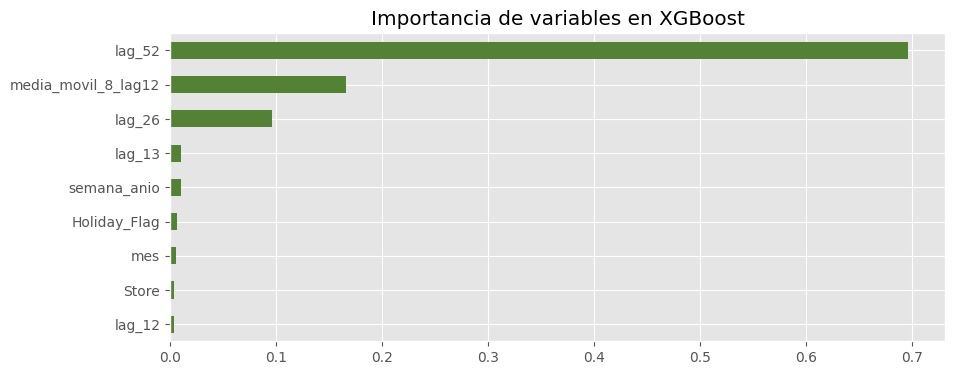

In [ ]:
imp = pd.Series(modelo_xgb.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(10, 4), color="#548235", title="Importancia de variables en XGBoost")
plt.show()

XGBoost depende casi por completo del **`lag_52`** (la venta de la misma semana del año anterior, ~70% de la importancia), seguido de la media móvil y el rezago de 26 semanas. Esto coincide con el EDA: el rezago 52 es la variable más informativa. `Holiday_Flag` pesa poco porque el `lag_52` ya "sabe" cuándo hubo feriado el año anterior.

## **5.6 Mejora propuesta: Ensamble Chronos-Bolt + XGBoost**

Chronos solo "ve" la historia de ventas (es univariado), mientras que XGBoost aprovecha el calendario, la marca de feriado y el rezago de 52 semanas. Como fallan en situaciones distintas, promediamos ambos pronósticos (50/50), una técnica simple y muy usada en competencias de forecasting (M4/M5).

In [ ]:
pred_ensamble = (pred_chronos + pred_xgb) / 2
print("Ensamble Chronos + XGBoost:", {k: round(v, 2) for k, v in metricas(Y_test, pred_ensamble).items()})

Ensamble Chronos + XGBoost: {'MAE': 39417.93, 'RMSE': 59137.2, 'MAPE (%)': 3.84, 'WAPE (%)': 3.84}


El ensamble obtiene **WAPE 3.84% y MAPE 3.84%**, mejor que cada modelo por separado (Chronos 4.61%, XGBoost 4.21%). Chronos aporta una lectura robusta del nivel reciente y XGBoost aporta la memoria del año anterior, y sus errores se compensan.

## **5.7 COMPARACIÓN: Chronos-Bolt (Zero-Shot) vs. modelos tradicionales**

In [ ]:
modelos = {
    "Ensamble Chronos + XGBoost": (pred_ensamble, tiempo_chronos + tiempo_xgb, "Sí (solo XGBoost)"),
    "Chronos-Bolt (Zero-Shot)": (pred_chronos, tiempo_chronos, "No"),
    "XGBoost (global)": (pred_xgb, tiempo_xgb, "Sí (1 modelo)"),
    "Prophet": (pred_prophet, tiempo_prophet, "Sí (45 modelos)"),
    "Auto-ARIMA": (pred_arima, tiempo_arima, "Sí (45 modelos)"),
    "Naive estacional": (pred_snaive, 0.0, "No"),
    "Naive": (pred_naive, 0.0, "No"),
}
comparacion = pd.DataFrame([{"Modelo": n, **metricas(Y_test, p), "Tiempo (s)": t, "¿Entrena?": e}
                            for n, (p, t, e) in modelos.items()]).sort_values("WAPE (%)").reset_index(drop=True)
comparacion

,Modelo,MAE,RMSE,MAPE (%),WAPE (%),Tiempo (s),¿Entrena?
0,Ensamble Chronos + XGBoost,"39,417.93","59,137.20",3.84,3.84,0.97,Sí (solo XGBoost)
1,Prophet,"40,579.08","59,058.82",4.23,3.95,9.53,Sí (45 modelos)
2,XGBoost (global),"43,265.29","68,316.66",4.27,4.21,0.51,Sí (1 modelo)
3,Chronos-Bolt (Zero-Shot),"47,299.69","69,108.89",4.49,4.61,0.46,No
4,Naive estacional,"53,768.95","85,365.67",5.46,5.24,0.00,No
5,Naive,"59,239.97","85,346.23",6.01,5.77,0.00,No
6,Auto-ARIMA,"61,385.14","90,751.13",5.97,5.98,131.75,Sí (45 modelos)


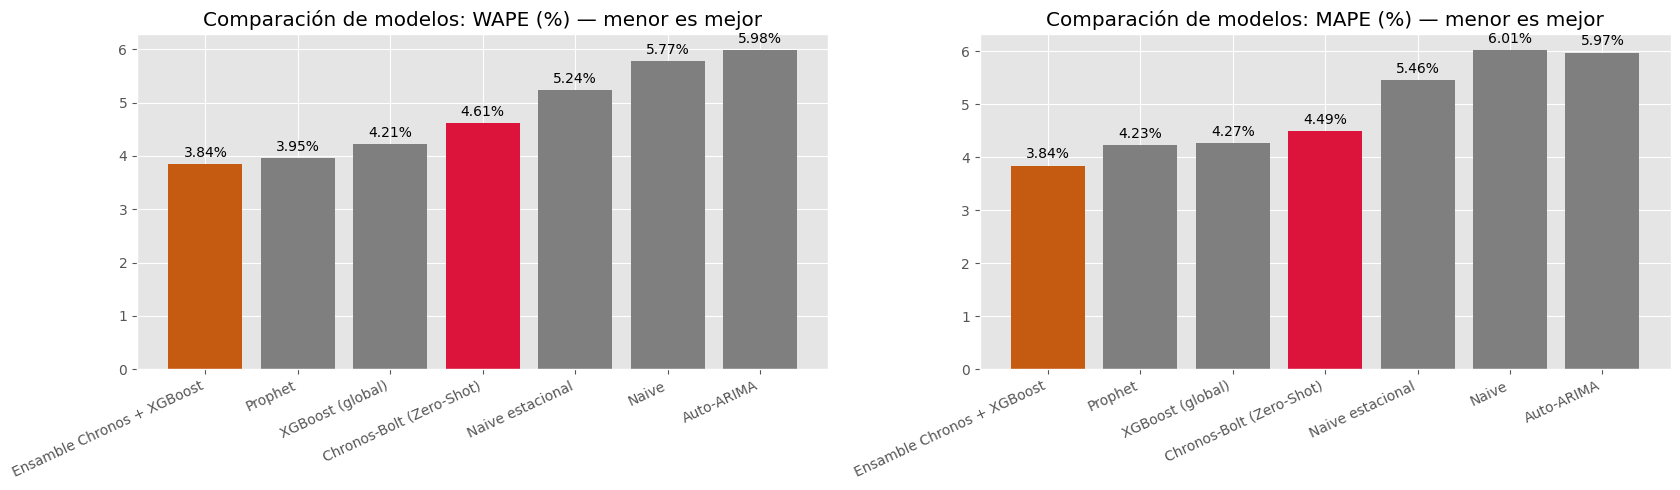

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
colores = ["#c55a11" if "Ensamble" in m else "crimson" if "Chronos" in m else "#7f7f7f" for m in comparacion["Modelo"]]
for ax, met in zip(axes, ["WAPE (%)", "MAPE (%)"]):
    barras = ax.bar(comparacion["Modelo"], comparacion[met], color=colores)
    ax.bar_label(barras, fmt="%.2f%%", padding=3)
    ax.set_title(f"Comparación de modelos: {met} — menor es mejor")
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
plt.tight_layout(); plt.show()

**Resultados en la ventana ago–oct 2012 (45 tiendas):**

* **Chronos-Bolt zero-shot (WAPE 4.61%) supera a todos los baselines y a Auto-ARIMA** (Naive estacional 5.24%, Naive 5.77%, Auto-ARIMA 5.98%) **sin haber visto nunca estos datos**, en **~0.5 s** frente a los **~132 s** que tardó Auto-ARIMA en ajustar 45 modelos.
* Queda por detrás de **Prophet (3.95%)** y **XGBoost (4.21%)**, que sí se ajustan a estas series y usan el calendario/feriados. En RMSE, Chronos (69.1 mil) casi empata con XGBoost (68.3 mil).
* El mejor resultado es el **Ensamble Chronos + XGBoost (3.84%)**, que supera incluso a Prophet.

Es decir: el TSFM es **competitivo** frente a los modelos tradicionales, y **combinado** con un modelo de features da el mejor pronóstico.

Número de tiendas donde cada modelo tiene el menor error:
Prophet                       15
Ensamble Chronos + XGBoost    11
Naive estacional               6
XGBoost (global)               4
Auto-ARIMA                     3
Naive                          3
Chronos-Bolt (Zero-Shot)       3


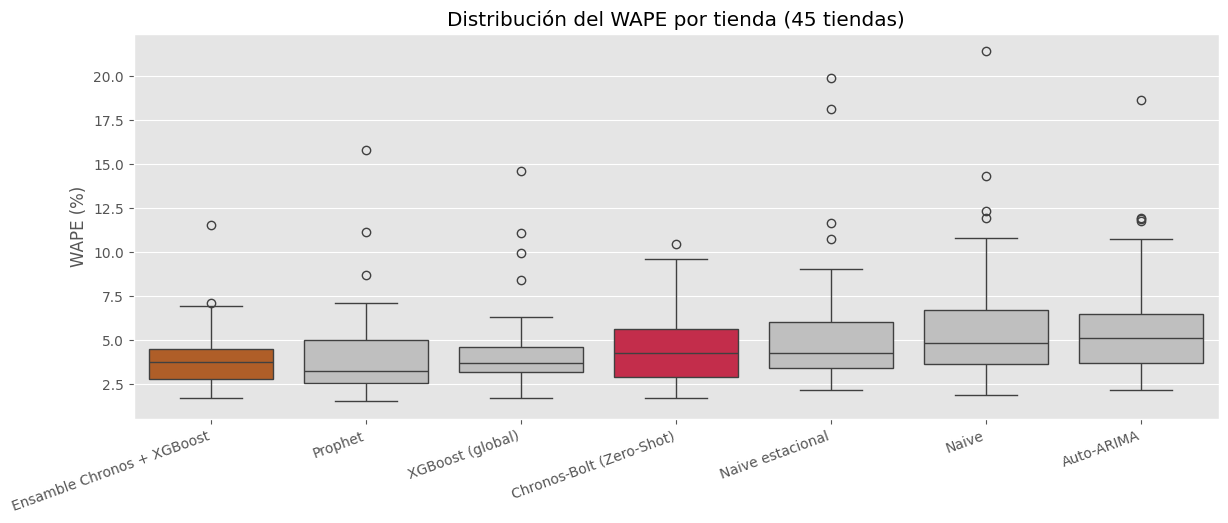

In [ ]:
# ¿En cuántas tiendas gana cada modelo? (WAPE por tienda)
wape_tienda = pd.DataFrame({n: [np.sum(np.abs(Y_test[i] - p[i])) / np.sum(Y_test[i]) * 100 for i in range(len(TIENDAS))]
                            for n, (p, _, _) in modelos.items()}, index=TIENDAS)
print("Número de tiendas donde cada modelo tiene el menor error:")
print(wape_tienda.idxmin(axis=1).value_counts().to_string())

plt.figure(figsize=(14, 5))
sns.boxplot(data=wape_tienda[comparacion["Modelo"]], palette=["#c55a11" if "Ensamble" in m else "crimson" if "Chronos" in m else "#bfbfbf" for m in comparacion["Modelo"]])
plt.title("Distribución del WAPE por tienda (45 tiendas)"); plt.ylabel("WAPE (%)"); plt.xticks(rotation=20, ha="right")
plt.show()

Viendo tienda por tienda, Prophet es el que más veces gana (15 tiendas) y el ensamble le sigue (11). Lo interesante del boxplot es el **peor caso**: Chronos no tiene tiendas con errores extremos (su máximo es ~10.5%), mientras que Prophet y XGBoost tienen tiendas con 15–16% de error. El **ensamble** tiene la caja más baja y compacta (casi todas las tiendas por debajo de 7%), lo que lo hace el más confiable para operar las 45 tiendas.

## **5.8 Validación robusta: *backtesting* con 4 ventanas (rolling origin)**

Una sola ventana de 12 semanas puede ser "suerte". Siguiendo la idea de validación *walk-forward*, repetimos el experimento en **4 ventanas consecutivas de 12 semanas**, cada una usando solo la historia disponible hasta su fecha de corte. La primera ventana (dic-2011 a feb-2012) incluye **la temporada navideña y el Super Bowl**, el periodo más difícil del año.

In [ ]:
%%time
fechas = np.sort(df["Date"].unique())
resultados_bt = []

for k in [4, 3, 2, 1]:
    corte, fin = fechas[-HORIZONTE * k - 1], fechas[-HORIZONTE * (k - 1) - 1]
    tr = df[df["Date"] <= corte]
    te = df[(df["Date"] > corte) & (df["Date"] <= fin)]
    Y = np.array([te.loc[te["Store"] == s, "Weekly_Sales"].values for s in TIENDAS])

    ctx = [torch.tensor(tr.loc[tr["Store"] == s, "Weekly_Sales"].values, dtype=torch.float32) for s in TIENDAS]
    q, _ = pipeline.predict_quantiles(inputs=ctx, prediction_length=HORIZONTE, quantile_levels=[0.1, 0.5, 0.9])
    preds = {"Chronos-Bolt (Zero-Shot)": q[:, :, 1].numpy()}
    preds["XGBoost (global)"] = pronostico_xgb(corte, fin)[0]
    preds["Ensamble Chronos + XGBoost"] = (preds["Chronos-Bolt (Zero-Shot)"] + preds["XGBoost (global)"]) / 2
    preds["Prophet"] = pronostico_prophet(tr, HORIZONTE)
    preds["Auto-ARIMA"] = np.array([auto_arima(tr.loc[tr["Store"] == s, "Weekly_Sales"].values, seasonal=False, stepwise=True,
                                               suppress_warnings=True, error_action="ignore").predict(n_periods=HORIZONTE) for s in TIENDAS])
    preds["Naive estacional"] = np.array([df.loc[(df["Store"] == s) & (df["Date"] > corte - np.timedelta64(52, "W")) &
                                                 (df["Date"] <= fin - np.timedelta64(52, "W")), "Weekly_Sales"].values for s in TIENDAS])
    cob = np.mean((Y >= q[:, :, 0].numpy()) & (Y <= q[:, :, 2].numpy())) * 100
    ventana = f"{pd.Timestamp(te['Date'].min()).date()} a {pd.Timestamp(te['Date'].max()).date()}"
    for n, p in preds.items():
        resultados_bt.append({"Ventana": ventana, "Modelo": n, **metricas(Y, p),
                              "Cobertura p10-p90 (%)": cob if n.startswith("Chronos") else np.nan})

bt = pd.DataFrame(resultados_bt)
tabla_bt = bt.pivot(index="Ventana", columns="Modelo", values="WAPE (%)")
tabla_bt = tabla_bt[[m for m in comparacion["Modelo"] if m in tabla_bt.columns]]
tabla_bt.loc["PROMEDIO"] = tabla_bt.mean()
tabla_bt

CPU times: user 12min 39s, sys: 2.78 s, total: 12min 41s
Wall time: 7min 58s


Modelo,Ensamble Chronos + XGBoost,Prophet,XGBoost (global),Chronos-Bolt (Zero-Shot),Naive estacional,Auto-ARIMA
Ventana,,,,,,
2011-12-02 a 2012-02-17,8.87,10.35,6.01,14.44,5.54,16.40
2012-02-24 a 2012-05-11,4.62,4.88,5.75,5.22,6.40,7.32
2012-05-18 a 2012-08-03,4.04,4.12,4.38,4.37,5.21,5.65
2012-08-10 a 2012-10-26,3.84,3.95,4.21,4.61,5.24,5.98
PROMEDIO,5.34,5.83,5.09,7.16,5.60,8.84


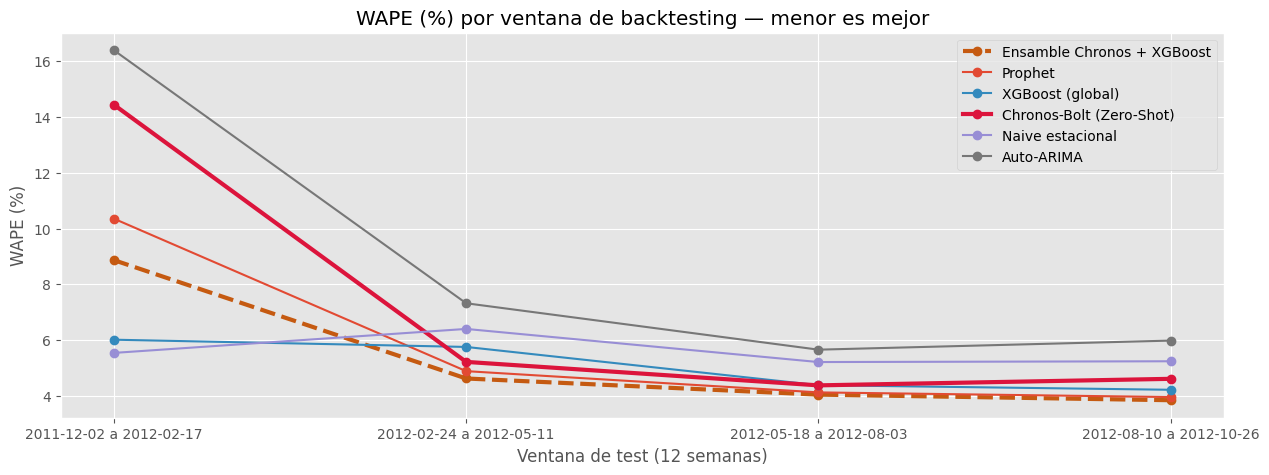

Cobertura p10-p90 de Chronos por ventana:
                Ventana  Cobertura p10-p90 (%)
2011-12-02 a 2012-02-17                  73.89
2012-02-24 a 2012-05-11                  90.37
2012-05-18 a 2012-08-03                  93.33
2012-08-10 a 2012-10-26                  95.37


In [ ]:
t = tabla_bt.drop("PROMEDIO")
plt.figure(figsize=(15, 5))
for m in t.columns:
    plt.plot(t.index, t[m], marker="o", lw=3 if "Chronos" in m else 1.5,
             color="#c55a11" if "Ensamble" in m else "crimson" if "Chronos" in m else None,
             ls="--" if "Ensamble" in m else "-", label=m)
plt.title("WAPE (%) por ventana de backtesting — menor es mejor")
plt.ylabel("WAPE (%)"); plt.xlabel("Ventana de test (12 semanas)"); plt.legend(); plt.show()

print("Cobertura p10-p90 de Chronos por ventana:")
print(bt.dropna(subset=["Cobertura p10-p90 (%)"])[["Ventana", "Cobertura p10-p90 (%)"]].to_string(index=False))

El backtesting cambia un poco la historia y es importante mostrarlo:

* En las tres ventanas **sin temporada navideña**, Chronos está al nivel de los mejores (**5.22%, 4.37% y 4.61%**), e incluso le gana a XGBoost en feb–may (5.22% vs 5.75%).
* En la ventana **dic-2011 a feb-2012**, Chronos sube a **14.44%**: no anticipó el pico de Navidad. Ahí ganan los modelos que usan explícitamente el año anterior (XGBoost 6.01% y Naive estacional 5.54%).
* En promedio de las 4 ventanas, el mejor es XGBoost (5.09%), seguido del **ensamble (5.34%)**, Naive estacional (5.60%), Prophet (5.83%), **Chronos (7.16%)** y Auto-ARIMA (8.84%).
* El **ensamble es el mejor en 3 de las 4 ventanas** y reduce el error navideño de Chronos de 14.44% a 8.87%.
* La cobertura p10–p90 de Chronos es de 90–95% en ventanas normales, pero baja a **73.9%** en Navidad: los intervalos también se quedan cortos en el pico.

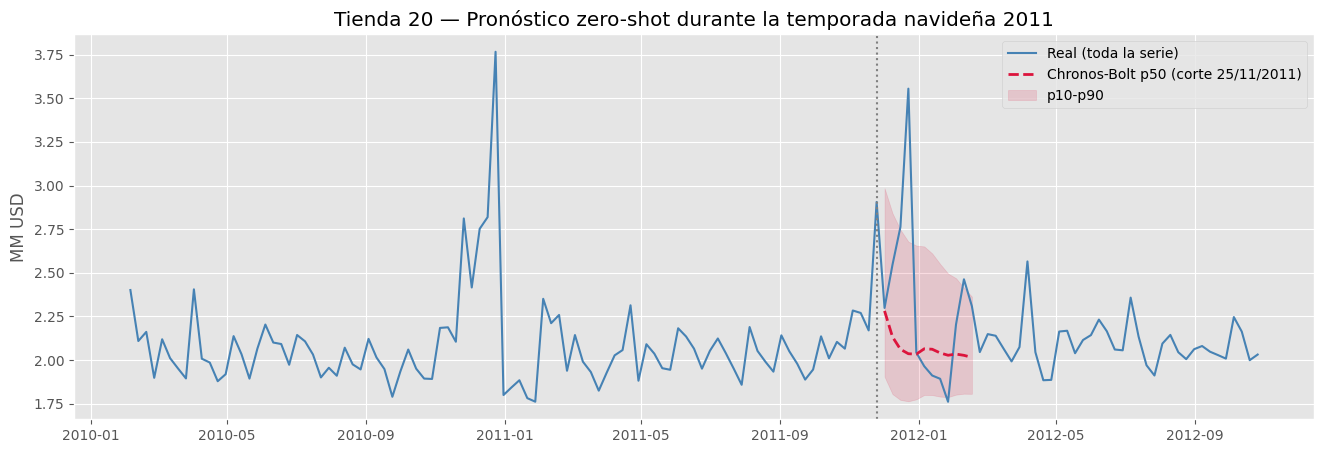

In [ ]:
# Zoom a la ventana navideña: ¿qué le pasó a Chronos en la Tienda 20?
corte = fechas[-HORIZONTE * 4 - 1]; fin = fechas[-HORIZONTE * 3 - 1]
d = df[df["Store"] == 20]
ctx = torch.tensor(d.loc[d["Date"] <= corte, "Weekly_Sales"].values, dtype=torch.float32)
q, _ = pipeline.predict_quantiles(inputs=ctx, prediction_length=HORIZONTE, quantile_levels=[0.1, 0.5, 0.9])
f_te = d.loc[(d["Date"] > corte) & (d["Date"] <= fin), "Date"]

plt.figure(figsize=(16, 5))
plt.plot(d["Date"], d["Weekly_Sales"] / 1e6, color="steelblue", label="Real (toda la serie)")
plt.plot(f_te, q[0, :, 1] / 1e6, color="crimson", ls="--", lw=2, label="Chronos-Bolt p50 (corte 25/11/2011)")
plt.fill_between(f_te, q[0, :, 0] / 1e6, q[0, :, 2] / 1e6, color="crimson", alpha=0.15, label="p10-p90")
plt.axvline(pd.Timestamp(corte), color="gray", ls=":")
plt.title("Tienda 20 — Pronóstico zero-shot durante la temporada navideña 2011")
plt.ylabel("MM USD"); plt.legend(); plt.show()

Este zoom explica el problema: con corte al 25/11/2011, Chronos tenía solo 95 semanas de contexto, con **un único diciembre previo** (2010). Como es zero-shot y univariado, no "sabe" que ese pico es un evento de calendario que se repite, así que proyectó un regreso al nivel normal y **se perdió el pico de 3.55 millones** de la semana de Navidad. XGBoost sí lo captura porque le damos el `lag_52` directamente. Es una limitación conocida de los TSFM con historias cortas y eventos anuales, y es la razón por la que en producción proponemos el ensamble.

# <font color=orange>**6.- Propuesta de despliegue en producción**</font>

La propuesta aprovecha la principal ventaja del TSFM: **no hay que entrenar ni mantener 45 modelos**. El flujo semanal sería:

1. **Ingesta:** las ventas de los puntos de venta (POS) y el ERP llegan al *data lake*; un job de **PySpark** (Databricks o Dataproc) las limpia y agrega a nivel tienda-semana, igual que hicimos en el EDA.
2. **Orquestación:** Airflow / Cloud Composer dispara el pipeline cada lunes.
3. **Inferencia:** un contenedor con **Chronos-Bolt** (descargado de Hugging Face) + el XGBoost liviano genera las 12 semanas siguientes para todas las tiendas.
4. **Almacenamiento y consumo:** los cuantiles se guardan en una tabla (BigQuery / Delta) y se consumen desde un dashboard y una API.
5. **Monitoreo:** cada semana se compara lo pronosticado con lo real y se generan alertas.

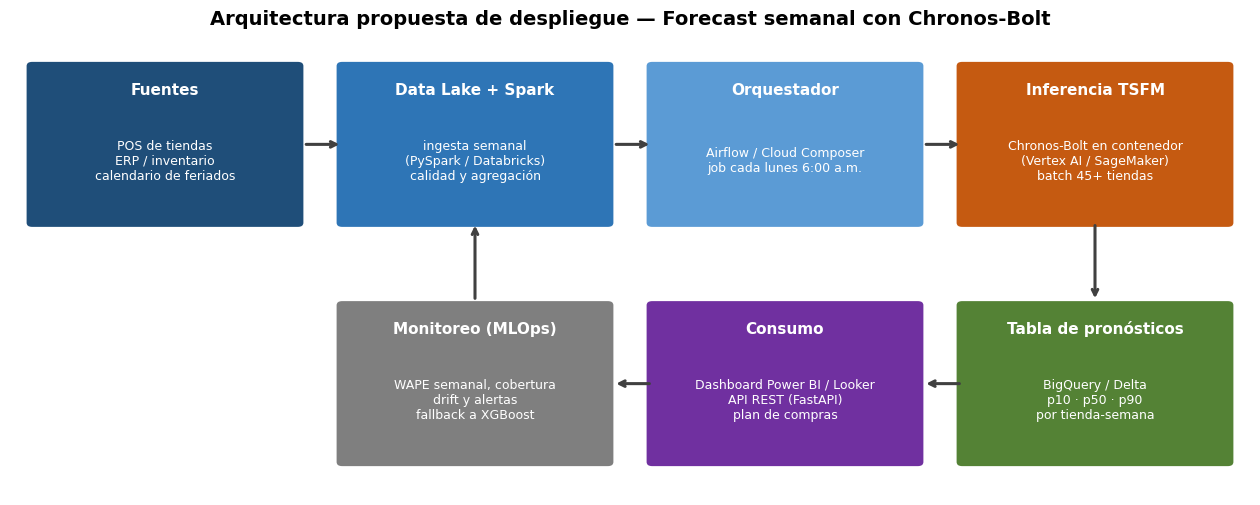

In [ ]:
from matplotlib.patches import FancyBboxPatch

capas = [
    (0.2, 3.3, "Fuentes", "POS de tiendas\nERP / inventario\ncalendario de feriados", "#1f4e79"),
    (3.0, 3.3, "Data Lake + Spark", "ingesta semanal\n(PySpark / Databricks)\ncalidad y agregación", "#2e75b6"),
    (5.8, 3.3, "Orquestador", "Airflow / Cloud Composer\njob cada lunes 6:00 a.m.", "#5b9bd5"),
    (8.6, 3.3, "Inferencia TSFM", "Chronos-Bolt en contenedor\n(Vertex AI / SageMaker)\nbatch 45+ tiendas", "#c55a11"),
    (8.6, 0.4, "Tabla de pronósticos", "BigQuery / Delta\np10 · p50 · p90\npor tienda-semana", "#548235"),
    (5.8, 0.4, "Consumo", "Dashboard Power BI / Looker\nAPI REST (FastAPI)\nplan de compras", "#7030a0"),
    (3.0, 0.4, "Monitoreo (MLOps)", "WAPE semanal, cobertura\ndrift y alertas\nfallback a XGBoost", "#7f7f7f"),
]
fig, ax = plt.subplots(figsize=(16, 6)); ax.set_xlim(0, 11.2); ax.set_ylim(0, 5.6); ax.axis("off")
for x, y, t, d, c in capas:
    ax.add_patch(FancyBboxPatch((x, y), 2.4, 1.9, boxstyle="round,pad=0.05", fc=c, ec="none"))
    ax.text(x + 1.2, y + 1.55, t, ha="center", color="white", weight="bold", fontsize=11)
    ax.text(x + 1.2, y + 0.75, d, ha="center", va="center", color="white", fontsize=9)
flechas = [((2.65, 4.25), (3.0, 4.25)), ((5.45, 4.25), (5.8, 4.25)), ((8.25, 4.25), (8.6, 4.25)),
           ((9.8, 3.3), (9.8, 2.35)), ((8.6, 1.35), (8.25, 1.35)), ((5.8, 1.35), (5.45, 1.35)), ((4.2, 2.35), (4.2, 3.3))]
for a, b in flechas:
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", lw=2.2, color="#404040"))
ax.set_title("Arquitectura propuesta de despliegue — Forecast semanal con Chronos-Bolt", fontsize=14, weight="bold")
plt.show()

### **6.1 Función de inferencia reutilizable (lo que correría el job semanal)**

Cada lunes el job lee la historia más reciente, llama a Chronos (sin entrenar), reajusta el XGBoost (menos de 1 segundo) y guarda los cuantiles y el pronóstico final del ensamble. Aquí lo simulamos generando el pronóstico **real a futuro** (las 12 semanas siguientes al último dato: noviembre 2012 – enero 2013) para las 45 tiendas, marcando como feriado las semanas de Thanksgiving y Navidad 2012.

In [ ]:
def pronosticar_demanda(historia: pd.DataFrame, horizonte: int = 12, semanas_feriado=()) -> pd.DataFrame:
    """Job semanal: devuelve por tienda y semana futura los cuantiles de Chronos (p10/p50/p90)
    y el pronóstico final del ensamble Chronos + XGBoost."""
    tiendas = sorted(historia["Store"].unique())
    futuras = pd.date_range(historia["Date"].max() + pd.Timedelta(weeks=1), periods=horizonte, freq="W-FRI")

    # 1) Chronos-Bolt zero-shot (sin entrenamiento)
    ctx = [torch.tensor(historia.loc[historia["Store"] == s, "Weekly_Sales"].values, dtype=torch.float32) for s in tiendas]
    q, _ = pipeline.predict_quantiles(inputs=ctx, prediction_length=horizonte, quantile_levels=[0.1, 0.5, 0.9])

    # 2) XGBoost: los lags >= 12 semanas ya se conocen para las 12 semanas futuras
    fut = pd.DataFrame([(s, f) for s in tiendas for f in futuras], columns=["Store", "Date"])
    fut["Holiday_Flag"] = fut["Date"].isin(pd.to_datetime(list(semanas_feriado))).astype(int)
    completo = crear_features(pd.concat([historia[["Store", "Date", "Weekly_Sales", "Holiday_Flag"]], fut]))
    entreno = completo[completo["Weekly_Sales"].notna()].dropna(subset=FEATURES)
    xgb_final = xgb.XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=5,
                                 subsample=0.8, colsample_bytree=0.8, random_state=42).fit(entreno[FEATURES], entreno["Weekly_Sales"])
    futuro_x = completo[completo["Weekly_Sales"].isna()].sort_values(["Store", "Date"])
    pred_x = xgb_final.predict(futuro_x[FEATURES]).reshape(len(tiendas), horizonte)

    filas = [{"Store": s, "Date": f, "p10": q[i, h, 0].item(), "p50_chronos": q[i, h, 1].item(), "p90": q[i, h, 2].item(),
              "xgboost": float(pred_x[i, h]), "pronostico_final": (q[i, h, 1].item() + float(pred_x[i, h])) / 2}
             for i, s in enumerate(tiendas) for h, f in enumerate(futuras)]
    return pd.DataFrame(filas)

# Feriados conocidos del próximo trimestre (misma convención del dataset): Thanksgiving y Navidad 2012
FERIADOS_2012 = ["2012-11-23", "2012-12-28"]

t0 = time.time()
forecast_futuro = pronosticar_demanda(df, HORIZONTE, FERIADOS_2012)
forecast_futuro["generado_el"] = pd.Timestamp.today().normalize()
forecast_futuro["modelo"] = "chronos-bolt-small + xgboost"
forecast_futuro.to_csv("forecast_walmart_12_semanas.csv", index=False)

print(f"Pronóstico futuro generado en {time.time() - t0:.2f} s -> {len(forecast_futuro)} filas guardadas en forecast_walmart_12_semanas.csv")
forecast_futuro.head(12)

Pronóstico futuro generado en 0.58 s -> 540 filas guardadas en forecast_walmart_12_semanas.csv


,Store,Date,p10,p50_chronos,p90,xgboost,pronostico_final,generado_el,modelo
0,1,2012-11-02,"1,469,773.00","1,643,704.62","1,859,272.25","1,755,273.75","1,699,489.19",2026-09-27,chronos-bolt-small + xgboost
1,1,2012-11-09,"1,527,445.88","1,723,706.62","1,986,700.38","1,660,421.62","1,692,064.12",2026-09-27,chronos-bolt-small + xgboost
2,1,2012-11-16,"1,474,449.38","1,684,980.12","1,982,145.38","1,618,983.25","1,651,981.69",2026-09-27,chronos-bolt-small + xgboost
3,1,2012-11-23,"1,451,177.50","1,691,982.62","2,023,620.25","2,053,105.00","1,872,543.81",2026-09-27,chronos-bolt-small + xgboost
4,1,2012-11-30,"1,503,337.00","1,761,792.38","2,125,016.00","1,656,869.75","1,709,331.06",2026-09-27,chronos-bolt-small + xgboost
5,1,2012-12-07,"1,548,196.75","1,830,853.88","2,222,033.50","1,865,843.75","1,848,348.81",2026-09-27,chronos-bolt-small + xgboost
6,1,2012-12-14,"1,547,048.75","1,835,160.12","2,224,748.50","1,890,363.38","1,862,761.75",2026-09-27,chronos-bolt-small + xgboost
7,1,2012-12-21,"1,520,876.75","1,805,552.50","2,184,584.25","2,280,388.50","2,042,970.50",2026-09-27,chronos-bolt-small + xgboost
8,1,2012-12-28,"1,465,363.75","1,701,989.75","2,045,472.25","1,649,184.75","1,675,587.25",2026-09-27,chronos-bolt-small + xgboost
9,1,2013-01-04,"1,476,126.62","1,688,819.88","2,013,010.75","1,632,393.75","1,660,606.81",2026-09-27,chronos-bolt-small + xgboost


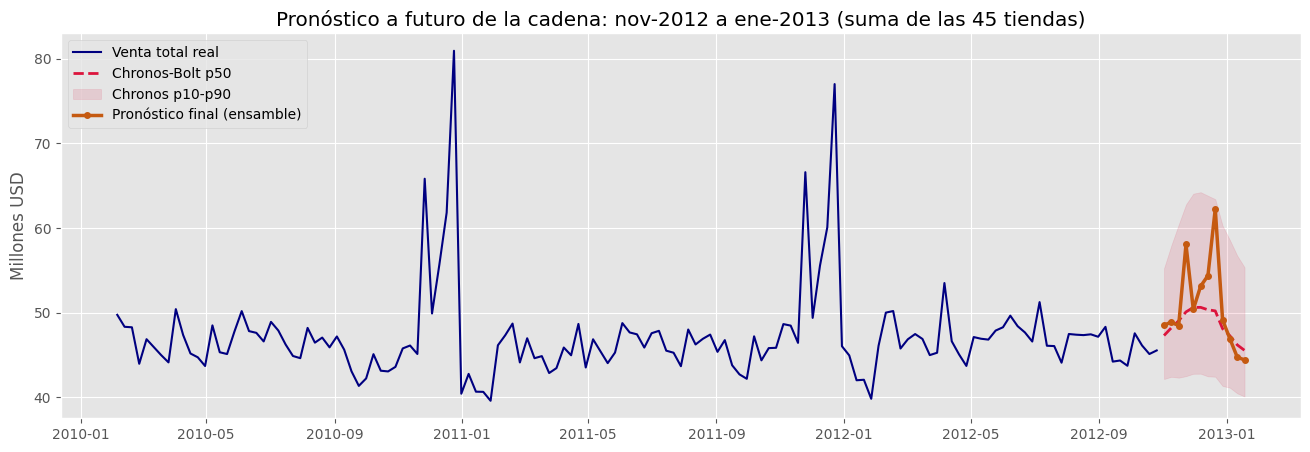

            p50_chronos  xgboost  pronostico_final
Date                                              
2012-11-02        47.30    49.70             48.50
2012-11-09        48.20    49.60             48.90
2012-11-16        49.00    47.90             48.50
2012-11-23        50.10    66.00             58.10
2012-11-30        50.60    50.20             50.40
2012-12-07        50.60    55.60             53.10
2012-12-14        50.30    58.40             54.40
2012-12-21        50.20    74.30             62.30
2012-12-28        48.10    50.20             49.20
2013-01-04        47.30    46.60             46.90
2013-01-11        46.20    43.30             44.80
2013-01-18        45.60    43.30             44.40


In [ ]:
tot_fut = forecast_futuro.groupby("Date")[["p10", "p50_chronos", "p90", "xgboost", "pronostico_final"]].sum() / 1e6
plt.figure(figsize=(16, 5))
plt.plot(total["Date"], total["Weekly_Sales"] / 1e6, color="navy", label="Venta total real")
plt.plot(tot_fut.index, tot_fut["p50_chronos"], color="crimson", ls="--", lw=2, label="Chronos-Bolt p50")
plt.fill_between(tot_fut.index, tot_fut["p10"], tot_fut["p90"], color="crimson", alpha=0.12, label="Chronos p10-p90")
plt.plot(tot_fut.index, tot_fut["pronostico_final"], color="#c55a11", lw=2.5, marker="o", ms=4, label="Pronóstico final (ensamble)")
plt.title("Pronóstico a futuro de la cadena: nov-2012 a ene-2013 (suma de las 45 tiendas)")
plt.ylabel("Millones USD"); plt.legend(loc="upper left"); plt.show()

print(tot_fut[["p50_chronos", "xgboost", "pronostico_final"]].round(1).to_string())

Este es el entregable que recibiría el área de compras. **Chronos solo** proyecta una demanda casi plana (~47–51 millones por semana), igual que en el backtesting navideño. En cambio, **XGBoost anticipa Thanksgiving (66.0 millones el 23/11) y la semana previa a Navidad (74.3 millones el 21/12)**, y el **pronóstico final del ensamble** queda en 58.1 y 62.3 millones para esas semanas. Comparado con 2011 (66.6 y 77.0 millones), el ensamble todavía es conservador en los picos, así que en temporada alta el plan de inventario debería apoyarse en la parte alta del intervalo (p90) o dar más peso a XGBoost, tal como se indica en el plan de operación.

### **6.2 Servicio API (esqueleto con FastAPI)**

Para que otros sistemas (ERP, compras, dashboards) consuman el pronóstico en línea, se expone una API. El archivo se genera con `%%writefile` y en producción se empaqueta en un contenedor Docker (ej. Cloud Run o SageMaker Endpoint).

In [ ]:
%%writefile api_forecast.py
from fastapi import FastAPI
from pydantic import BaseModel
import torch
from chronos import BaseChronosPipeline

app = FastAPI(title="API Forecast de Demanda - Chronos-Bolt")
pipeline = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu", torch_dtype=torch.float32)

class Solicitud(BaseModel):
    tienda: int
    historia: list[float]      # ventas semanales, de la más antigua a la más reciente
    horizonte: int = 12

@app.post("/forecast")
def forecast(req: Solicitud):
    q, _ = pipeline.predict_quantiles(inputs=torch.tensor(req.historia), prediction_length=req.horizonte,
                                      quantile_levels=[0.1, 0.5, 0.9])
    return {"tienda": req.tienda, "p10": q[0, :, 0].tolist(), "p50": q[0, :, 1].tolist(), "p90": q[0, :, 2].tolist()}

Overwriting api_forecast.py


### **6.3 Plan de operación y monitoreo (MLOps)**

| Aspecto | Propuesta |
|---|---|
| **Frecuencia** | Job batch cada lunes: Spark consolida las ventas de la semana y Chronos genera 12 semanas hacia adelante para todas las tiendas en segundos. |
| **Infraestructura** | Contenedor con el modelo (≈190 MB) en Vertex AI / SageMaker / Cloud Run; CPU es suficiente para 45 series, GPU solo si se escala a miles de tienda-departamento. |
| **Uso del intervalo** | p50 para el plan base de compras; **p90 para stock de seguridad** en productos críticos; p10 para escenarios conservadores de caja. |
| **Monitoreo** | Cada semana se compara el pronóstico con lo real: WAPE por tienda, cobertura p10–p90 y alertas si el WAPE supera 8% dos semanas seguidas. |
| **Temporada alta** | Para Thanksgiving–Navidad usar un **ensamble Chronos + XGBoost** (XGBoost aporta los lags de 52 semanas y el calendario de feriados) o un TSFM con covariables (Chronos-2 / TimesFM con regresores). |
| **Fallback** | Si el servicio del modelo falla, se publica el pronóstico de XGBoost o el Naive estacional para no dejar sin plan a las tiendas. |
| **Gobierno** | Versionar modelo y datos (MLflow), registrar cada corrida con fecha, versión del modelo y métricas. |

# <font color=orange>**7.- Conclusiones**</font>

* **Problema resuelto:** construimos un pipeline completo en Python (Kaggle → PySpark → EDA → TSFM → evaluación → despliegue) para pronosticar 12 semanas de ventas de las **45 tiendas de Walmart**.
>
* **Chronos-Bolt funcionó en modo zero-shot**: sin entrenar nada logró **WAPE 4.61% / MAPE 4.49%** en ago–oct 2012, **mejor que Auto-ARIMA, Naive y Naive estacional**, y pronosticó las 45 tiendas en **menos de 1 segundo** con **intervalos de incertidumbre** nativos.
>
* **Frente a los modelos tradicionales ajustados**, Prophet (3.95%) y XGBoost (4.21%) fueron algo más precisos en esa ventana, porque aprovechan el calendario y el rezago anual.
>
* **Limitación encontrada:** con solo ~2 años de historia, Chronos **no anticipa el pico navideño** (WAPE 14.44% en dic-2011). Los TSFM univariados necesitan más contexto o covariables para eventos anuales.
>
* **Mejor solución:** el **ensamble Chronos + XGBoost** obtuvo el menor error en la ventana principal (**3.84%**), fue el mejor en 3 de 4 ventanas de backtesting y redujo el error navideño de Chronos a 8.87%.
>
* **Tokenización y arquitectura:** comprobamos dentro del propio modelo cómo Chronos-Bolt normaliza la serie, la corta en parches de 16 semanas (tokens) y la procesa con un Transformer encoder-decoder T5, frente a la cuantización en 4,096 bins del Chronos original.
>
* **Despliegue:** proponemos un job batch semanal orquestado (Spark + Chronos + XGBoost en contenedor), con tabla de pronósticos p10/p50/p90, API, dashboard y monitoreo de WAPE y cobertura.
>
* **Trabajo futuro:** probar TSFM con covariables (Chronos-2, TimesFM con regresores), hacer *fine-tuning* de Chronos con las 45 tiendas y bajar el nivel a tienda-departamento, donde la ventaja de no entrenar miles de modelos se vuelve aún mayor.

In [ ]:
spark.stop()